## 🔄 RECONNEXION GOOGLE COLAB

**À lancer à chaque reconnexion ou redémarrage de l'environnement d'exécution.**

Cette section permet de retrouver les données du projet et le modèle CNN déjà entraîné, sans avoir à télécharger à nouveau MVTec AD ni à relancer les 30 époques d'entraînement.

**Procédure :**
1. Activer le GPU T4 dans les paramètres d'exécution.
2. Exécuter la cellule de restauration Google Drive ci-dessous.
3. Réinitialiser les variables nécessaires et charger les poids du CNN.
4. Reprendre les expérimentations à la dernière cellule non terminée.

**Attention :** ne pas réexécuter la cellule d'entraînement CNN lors d'une simple reconnexion.

# ***0. Initialisation rapide — Sélection du mode***

**🔄 À lancer à chaque reconnexion Google Colab.**

- `reconnexion` : restaure le dataset, les paramètres et le modèle entraîné.
- `experimentation` : restaure également les résultats nécessaires aux analyses.

L'entraînement du CNN reste désactivé par défaut afin d'éviter toute consommation inutile de ressources GPU.

In [ ]:
# Sélection interactive du mode de fonctionnement

print("=== INITIALISATION DU PROJET ===")
print("1 - Reconnexion : restauration du projet")
print("2 - Expérimentation : restauration et analyses")

choix = input("\nChoisissez un mode (1 ou 2) : ").strip()

while choix not in ("1", "2"):
    choix = input(
        "Choix invalide. Entrez 1 ou 2 : "
    ).strip()

MODE = {
    "1": "reconnexion",
    "2": "experimentation"
}[choix]

# Protection de l'entraînement
RUN_TRAINING = False

print(f"\nMode sélectionné : {MODE}")
print(f"Réentraînement autorisé : {RUN_TRAINING}")

=== INITIALISATION DU PROJET ===
1 - Reconnexion : restauration du projet
2 - Expérimentation : restauration et analyses

Choisissez un mode (1 ou 2) : 2

Mode sélectionné : experimentation
Réentraînement autorisé : False


***0.1 — Connexion à Google Drive et restauration du dataset***

**À exécuter à chaque nouvelle session Google Colab.**

Cette cellule :
- Monte Google Drive.
- Définit les répertoires locaux et permanents du projet.
- Vérifie la disponibilité du dataset MVTec AD `bottle`.
- Restaure le dataset lorsqu'il est absent du stockage permanent.

Si le dataset est déjà disponible sur Google Drive, aucun téléchargement n'est effectué.

Aucun modèle CNN n'est entraîné.

In [ ]:
from pathlib import Path
import shutil
import subprocess
import sys

# Répertoire temporaire de travail Colab
PROJECT_DIR = Path("/content/industrial-anomaly-detection")

# Répertoire permanent du projet sur Drive
DRIVE_PROJECT = Path("/content/drive/MyDrive/industrial-anomaly-detection")

# Dataset local éventuel
LOCAL_DATASET = PROJECT_DIR / "data/mvtec/bottle"

# Dataset permanent
DRIVE_DATASET = DRIVE_PROJECT / "data/mvtec/bottle"

# Montage de Google Drive si nécessaire
from google.colab import drive
drive.mount("/content/drive")

# Vérification de la structure
def dataset_valid(path):
    return all(
        (path / folder).is_dir()
        for folder in ["train/good", "test", "ground_truth"]
    )

if dataset_valid(DRIVE_DATASET):
    print("Dataset déjà disponible sur Google Drive.")

elif dataset_valid(LOCAL_DATASET):
    print("Dataset local trouvé. Copie vers Drive...")

    DRIVE_DATASET.parent.mkdir(
        parents=True, exist_ok=True
    )
    shutil.copytree(
        LOCAL_DATASET,
        DRIVE_DATASET,
        dirs_exist_ok=True
    )

else:
    print("Dataset absent. Téléchargement...")

    # Version compatible avec les dépendances Colab
    subprocess.check_call([
        sys.executable, "-m", "pip", "install",
        "-q", "huggingface-hub>=1.32,<2"
    ])

    from huggingface_hub import snapshot_download

    snapshot_download(
        repo_id="foersben/mvtec-ad",
        repo_type="dataset",
        allow_patterns=["bottle/**"],
        local_dir=str(DRIVE_DATASET.parent)
    )

# Vérification finale
assert dataset_valid(DRIVE_DATASET), ("Le dataset n'a pas pu être restauré.")

BOTTLE_DIR = DRIVE_DATASET

print("\nDataset restauré avec succès.")
print("Chemin :", BOTTLE_DIR)
print("Images d'entraînement :", len(list((BOTTLE_DIR / "train/good").glob("*.png"))))

Mounted at /content/drive
Dataset déjà disponible sur Google Drive.

Dataset restauré avec succès.
Chemin : /content/drive/MyDrive/industrial-anomaly-detection/data/mvtec/bottle
Images d'entraînement : 209


***0.2 — Vérification des sauvegardes et du périphérique***

**À exécuter à chaque nouvelle session Google Colab.**

Cette cellule :
- Vérifie la présence du dataset permanent.
- Vérifie la présence du modèle CNN entraîné.
- Détecte le GPU disponible.
- Initialise le périphérique PyTorch.

Google Drive étant déjà monté dans la cellule 0.1, il n'est pas monté une seconde fois.

Aucun entraînement n'est effectué.

In [ ]:
from pathlib import Path
import torch

# Chemins du projet
assert "PROJECT_DIR" in globals()
assert "DRIVE_PROJECT" in globals()

BOTTLE_DIR = DRIVE_PROJECT / "data/mvtec/bottle"
model_path = DRIVE_PROJECT / "models/autoencoder_bottle_best.pth"

# Vérification des sauvegardes
dataset_ok = (
    (BOTTLE_DIR / "train/good").is_dir()
    and (BOTTLE_DIR / "test").is_dir()
    and (BOTTLE_DIR / "ground_truth").is_dir()
)

model_ok = model_path.is_file()

print("Dataset disponible :", dataset_ok)
print("Modèle CNN disponible :", model_ok)

# Sélection du périphérique de calcul
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Périphérique :", device)

if device.type == "cuda":
    print("GPU :", torch.cuda.get_device_name(0))

# Arrêt explicite si les sauvegardes sont absentes
assert dataset_ok, (
    "Dataset bottle absent de Google Drive. "
    "Vérifier la sauvegarde permanente."
)

assert model_ok, (
    "Modèle CNN absent de Google Drive. "
    "Vérifier autoencoder_bottle_best.pth."
)

print("\n✅ Sauvegardes vérifiées. Prêt pour la restauration.")

Dataset disponible : True
Modèle CNN disponible : True
Périphérique : cuda
GPU : Tesla T4

✅ Sauvegardes vérifiées. Prêt pour la restauration.


***0.3 — Restauration de la référence OpenCV et des seuils***

**🔄 À lancer à chaque reconnexion Google Colab.**

Cette cellule restaure automatiquement :
- L'image moyenne de référence (`reference_image`).
- Le seuil de segmentation (`pixel_threshold`).
- Le seuil de classification (`image_threshold`).
- La séparation des images normales en entraînement et validation.

**Fonctionnement :**
- Première exécution : calcul et sauvegarde sur Google Drive.
- Exécutions suivantes : chargement direct des paramètres sauvegardés.

Aucun entraînement CNN n'est effectué.

In [ ]:
import cv2
import numpy as np
from pathlib import Path
from sklearn.model_selection import train_test_split
import time

start = time.time()

# 1. Paramètres utilisés dans notre méthode OpenCV
IMG_SIZE = 256
SEED = 42

# Chemin de sauvegarde permanente
config_dir = DRIVE_PROJECT / "checkpoints"
config_dir.mkdir(parents=True, exist_ok=True)

opencv_path = config_dir / "opencv_bottle_reference.npz"

# 2. Reconstitution de la séparation train / validation
image_paths = sorted(
    (BOTTLE_DIR / "train" / "good").glob("*.png")
)

assert len(image_paths) == 209, (
    f"209 images attendues, {len(image_paths)} trouvées."
)

train_paths, val_paths = train_test_split(
    image_paths,
    test_size=0.2,
    random_state=SEED,
    shuffle=True
)

# 3. Restaurer ou calculer les paramètres
if opencv_path.exists():

    print("Chargement de la référence OpenCV depuis Drive...")

    with np.load(opencv_path) as saved:
        reference_image = saved["reference_image"]
        pixel_threshold = float(saved["pixel_threshold"])
        image_threshold = float(saved["image_threshold"])

else:

    print("Première exécution : calcul de la référence...")

    image_sum = np.zeros((IMG_SIZE, IMG_SIZE, 3), dtype=np.float64
    )

    # Référence construite uniquement sur les images normales train
    for path in train_paths:

        img = cv2.imread(str(path))
        assert img is not None, f"Image illisible : {path}"

        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)

        image_sum += img.astype(np.float32) / 255.0

    reference_image = (image_sum / len(train_paths)).astype(np.float32)

    # Calibration avec les images normales de validation
    val_maps = []

    for path in val_paths:

        img = cv2.imread(str(path))
        assert img is not None, f"Image illisible : {path}"

        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(
            img, (IMG_SIZE, IMG_SIZE),
            interpolation=cv2.INTER_AREA
        )
        img = img.astype(np.float32) / 255.0

        difference = cv2.absdiff(img, reference_image)
        anomaly = np.mean(difference, axis=2)
        anomaly = cv2.GaussianBlur(
            anomaly, (5, 5), 0
        )

        val_maps.append(anomaly)

    val_maps = np.stack(val_maps)

    pixel_threshold = float(
        np.percentile(val_maps, 99.5)
    )

    val_scores = np.percentile(
        val_maps, 99, axis=(1, 2)
    )

    image_threshold = float(
        np.percentile(val_scores, 95)
    )

    # 4. Sauvegarde permanente
    np.savez_compressed(
        opencv_path,
        reference_image=reference_image,
        pixel_threshold=pixel_threshold,
        image_threshold=image_threshold
    )

    print("Paramètres enregistrés sur Drive.")

# 5. Vérification
assert reference_image.shape == (256, 256, 3)

print("\n=== OpenCV restauré ===")
print("Images train :", len(train_paths))
print("Images validation :", len(val_paths))
print("Dimensions référence :", reference_image.shape)
print(f"Seuil pixel : {pixel_threshold:.6f}")
print(f"Seuil image : {image_threshold:.6f}")
print(f"Temps : {time.time() - start:.2f} s")

Chargement de la référence OpenCV depuis Drive...

=== OpenCV restauré ===
Images train : 167
Images validation : 42
Dimensions référence : (256, 256, 3)
Seuil pixel : 0.207408
Seuil image : 0.244657
Temps : 1.37 s


***0.4 — Restauration de l'autoencodeur CNN***

**🔄 À lancer à chaque reconnexion Google Colab.**

Cette cellule reconstruit l'architecture de l'autoencodeur et recharge les poids du meilleur modèle entraîné.

- Modèle : autoencodeur convolutif PyTorch.
- Dataset : MVTec AD — bottle.
- GPU : Tesla T4, si disponible.
- Entraînement : aucun.

Le modèle est directement placé en mode évaluation (`eval`).

In [ ]:
import torch
import torch.nn as nn
import time

start = time.time()

# 1. Architecture identique au modèle entraîné
class ConvAutoencoder(nn.Module):

    def __init__(self):
        super().__init__()

        # Encodeur
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 32, 3, stride=2, padding=1),
            nn.ReLU(inplace=True),

            nn.Conv2d(32, 64, 3, stride=2, padding=1),
            nn.ReLU(inplace=True),

            nn.Conv2d(64, 128, 3, stride=2, padding=1),
            nn.ReLU(inplace=True),

            nn.Conv2d(128, 256, 3, stride=2, padding=1),
            nn.ReLU(inplace=True)
        )

        # Décodeur
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(
                256, 128, 4, stride=2, padding=1
            ),
            nn.ReLU(inplace=True),

            nn.ConvTranspose2d(
                128, 64, 4, stride=2, padding=1
            ),
            nn.ReLU(inplace=True),

            nn.ConvTranspose2d(
                64, 32, 4, stride=2, padding=1
            ),
            nn.ReLU(inplace=True),

            nn.ConvTranspose2d(
                32, 3, 4, stride=2, padding=1
            ),
            nn.Sigmoid()
        )

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z)


# 2. Création du modèle sur le périphérique choisi
model = ConvAutoencoder().to(device)

# 3. Chargement des poids sauvegardés
assert model_path.is_file(), (
    f"Modèle introuvable : {model_path}"
)

state_dict = torch.load(
    model_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(state_dict)

# 4. Activation du mode évaluation
model.eval()

# 5. Vérification avec un tenseur de test
with torch.inference_mode():
    sample = torch.zeros(
        1, 3, 256, 256,
        device=device
    )

    output = model(sample)

assert output.shape == sample.shape

# 6. Résumé
parameters = sum(
    p.numel() for p in model.parameters()
)

print("=== Autoencodeur CNN restauré ===")
print("Modèle :", model_path.name)
print("Périphérique :", device)
print("Paramètres :", f"{parameters:,}")
print("Entrée :", tuple(sample.shape))
print("Sortie :", tuple(output.shape))
print("Mode évaluation :", not model.training)
print(f"Temps : {time.time() - start:.2f} s")
print("\n✅ CNN prêt pour l'inférence.")

=== Autoencodeur CNN restauré ===
Modèle : autoencoder_bottle_best.pth
Périphérique : cuda
Paramètres : 1,078,307
Entrée : (1, 3, 256, 256)
Sortie : (1, 3, 256, 256)
Mode évaluation : True
Temps : 3.92 s

✅ CNN prêt pour l'inférence.


***0.5 — Restauration des seuils CNN***

**🧪 À exécuter en mode expérimentation.**

Cette cellule charge les seuils de classification et de segmentation du CNN depuis Google Drive.

Lors de la première exécution, elle calcule les seuils à partir des 42 images normales de validation, puis les sauvegarde.

En mode reconnexion, elle est automatiquement ignorée.

**Aucun entraînement n'est effectué.**

In [ ]:
import numpy as np
import cv2
import torch
import time

if MODE == "experimentation":

    start = time.time()

    # Chemin permanent des seuils CNN
    cnn_config_path = DRIVE_PROJECT / "checkpoints/cnn_bottle_thresholds.npz"

    cnn_config_path.parent.mkdir(parents=True, exist_ok=True)

    # Charger les seuils s'ils existent déjà
    if cnn_config_path.exists():

        print("Chargement des seuils CNN depuis Drive...")

        with np.load(cnn_config_path) as saved:
            cnn_pixel_threshold = float(saved["cnn_pixel_threshold"])
            cnn_image_threshold = float(saved["cnn_image_threshold"])

    else:

        print("Première calibration du CNN...")

        cnn_val_maps = []
        model.eval()

        with torch.inference_mode():

            for path in val_paths:

                image = cv2.imread(str(path))
                assert image is not None, f"Image illisible : {path}"

                image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
                image = cv2.resize(image, (256, 256), interpolation=cv2.INTER_AREA)
                image = image.astype(np.float32) / 255.0

                tensor = torch.from_numpy(image.transpose(2, 0, 1).copy()).unsqueeze(0).to(device)
                reconstructed = model(tensor)

                error_map = torch.abs(tensor - reconstructed).mean(dim=1).squeeze(0).cpu().numpy()
                error_map = cv2.GaussianBlur(error_map, (5, 5), 0)

                cnn_val_maps.append(error_map)

        cnn_val_maps = np.stack(cnn_val_maps)

        # Seuil de segmentation
        cnn_pixel_threshold = float(np.percentile(cnn_val_maps, 99.5))

        # Seuil de classification
        cnn_val_scores = np.percentile(cnn_val_maps, 99, axis=(1, 2))

        cnn_image_threshold = float(np.percentile(cnn_val_scores, 95))

        # Sauvegarde sur Drive
        np.savez_compressed(cnn_config_path, cnn_pixel_threshold=cnn_pixel_threshold, cnn_image_threshold=cnn_image_threshold)

        print("Seuils CNN sauvegardés sur Drive.")

    print("\n=== Calibration CNN restaurée ===")
    print(f"Seuil pixel : {cnn_pixel_threshold:.6f}")
    print(f"Seuil image : {cnn_image_threshold:.6f}")
    print(f"Temps : {time.time() - start:.2f} s")

else:

    print("Mode reconnexion : calibration CNN ignorée.")

Chargement des seuils CNN depuis Drive...

=== Calibration CNN restaurée ===
Seuil pixel : 0.135156
Seuil image : 0.132067
Temps : 0.83 s


***0.6 — Restauration des paramètres CNN V2***

**🧪 À lancer en mode expérimentation.**

Charge les cartes statistiques et les seuils de normalisation spatiale depuis Google Drive.

Aucun entraînement ni recalcul des statistiques n'est effectué.

En mode reconnexion, cette cellule est ignorée.

In [ ]:
import numpy as np

if MODE == "experimentation":

    v2_path = (DRIVE_PROJECT / "checkpoints/cnn_bottle_spatial_v2.npz")

    assert v2_path.is_file(), "Paramètres V2 introuvables sur Google Drive."

    # Restauration des statistiques et des seuils
    with np.load(v2_path, allow_pickle=False) as saved:

        cnn_mean_map_v2 = saved["mean_map"]
        cnn_std_map_v2 = saved["std_map"]

        EPSILON_V2 = float(saved["epsilon"])

        cnn_pixel_threshold_v2 = float(
            saved["pixel_threshold"]
        )

        cnn_image_threshold_v2 = float(
            saved["image_threshold"]
        )

    # Vérification des dimensions
    assert cnn_mean_map_v2.shape == (256, 256)
    assert cnn_std_map_v2.shape == (256, 256)
    assert EPSILON_V2 > 0

    print("=== CNN V2 restauré ===")
    print(f"Seuil pixel : {cnn_pixel_threshold_v2:.6f}")
    print(f"Seuil image : {cnn_image_threshold_v2:.6f}")
    print(f"Epsilon : {EPSILON_V2}")
    print("Cartes statistiques :", cnn_mean_map_v2.shape)

    print("\nCNN V2 prêt pour les expérimentations.")

else:
    print("Mode reconnexion : restauration V2 ignorée.")

=== CNN V2 restauré ===
Seuil pixel : 2.403548
Seuil image : 2.337424
Epsilon : 0.02
Cartes statistiques : (256, 256)

CNN V2 prêt pour les expérimentations.


***0.7 — Restauration des paramètres CNN V3***

**🧪 À lancer en mode expérimentation.**

Cette cellule restaure automatiquement les paramètres de la méthode V3 depuis Google Drive.

Paramètres restaurés :
- Sigma du lissage gaussien.
- Seuil de segmentation V3.
- Seuil de classification V3.

Aucun entraînement ni recalcul des seuils n'est effectué.

**🔄 À lancer à chaque reconnexion en mode expérimentation.**

In [ ]:
import numpy as np

if MODE == "experimentation":

    # 1. Chemin permanent des paramètres V3
    v3_path = (DRIVE_PROJECT / "checkpoints/cnn_bottle_smoothing_v3.npz")

    assert v3_path.is_file(), "Paramètres V3 introuvables sur Google Drive"

    # 2. Chargement des paramètres
    with np.load(v3_path, allow_pickle=False) as saved:

        cnn_sigma_v3 = float(saved["sigma"])
        cnn_pixel_threshold_v3 = float(saved["pixel_threshold"])
        cnn_image_threshold_v3 = float(saved["image_threshold"])

    # 3. Vérif de cohérence
    assert cnn_sigma_v3 > 0, "Sigma invalide"
    assert cnn_pixel_threshold_v3 >= 0
    assert cnn_image_threshold_v3 >= 0

    # 4. Résumé
    print("=== CNN V3 restauré ===")
    print(f"Sigma gaussien : {cnn_sigma_v3:.6f}")
    print(f"Seuil pixel V3 : {cnn_pixel_threshold_v3:.6f}")
    print(f"Seuil image V3 : {cnn_image_threshold_v3}")
    print("\nCNN V3 prêt pour la segmentation.")

else:
    print("Mode reconnexion : restauration V3 ignorée.")

=== CNN V3 restauré ===
Sigma gaussien : 2.000000
Seuil pixel V3 : 1.534871
Seuil image V3 : 1.4561723470687866

CNN V3 prêt pour la segmentation.


***0.8 — Vérification générale de l'initialisation***

Cette cellule contrôle que les ressources nécessaires sont disponibles avant de poursuivre le notebook.

**Contrôles communs aux deux modes :**
- Dataset accessible.
- Référence OpenCV restaurée.
- Autoencodeur CNN chargé avec les bons poids.
- Modèle placé en mode évaluation.

**Contrôles supplémentaires en mode expérimentation :**
- Seuils CNN V1 disponibles.
- Cartes statistiques et seuils CNN V2 disponibles.
- Sigma et seuils CNN V3 disponibles.

Les évaluations expérimentales seront réalisées ultérieurement en section 5.

Aucun entraînement, recalibrage ou calcul d'inférence n'est effectué.


In [ ]:
import torch
import numpy as np

print("=== VERIFICATION DE LA SECTION 0 ===")

# =========================================================
# 1. Ressources communes
# =========================================================
assert MODE in ("reconnexion", "experimentation")
assert BOTTLE_DIR.is_dir(), "Dataset inaccessible"
assert model_path.is_file(), "Poids CNN introuvables"

assert reference_image.shape == (256, 256, 3)
assert np.isfinite(reference_image).all(), "Référence OpenCV contenant des images invalides."

assert isinstance(model, ConvAutoencoder), "Architecture CNN incorrecte."
assert not model.training, "CNN non placé en mode évaluation"

assert pixel_threshold >= 0
assert image_threshold >= 0

parameters = sum(p.numel() for p in model.parameters())
assert parameters == 1_078_307, "Nombre de paramètres CNN inattendu."

print("Dataset :", BOTTLE_DIR)
print("Référence OpenCV :", reference_image.shape)
print("Modèle CNN :", model_path.name)
print("Paramètres :", parameters)
print("Périphérique :", next(model.parameters()).device)
print("Mode :", MODE)

# ===========================================================
# 2. Ressources expérimentales
# ===========================================================
if MODE == "experimentation":
    # CNN V1
    assert np.isfinite(cnn_pixel_threshold)
    assert np.isfinite(cnn_image_threshold)

    assert cnn_pixel_threshold >= 0
    assert cnn_image_threshold >= 0

    print("\nCNN V1 : seuils disponibles")

    # CNN V2
    assert cnn_mean_map_v2.shape == (256, 256)
    assert cnn_std_map_v2.shape == (256, 256)

    assert np.isfinite(cnn_mean_map_v2).all()
    assert np.isfinite(cnn_std_map_v2).all()

    assert EPSILON_V2 > 0
    assert np.isfinite(cnn_image_threshold_v2)
    assert np.isfinite(cnn_pixel_threshold_v2)

    print("\nCNN V2 : paramètres disponibles")

    # CNN V3
    assert np.isfinite(cnn_sigma_v3)
    assert np.isfinite(cnn_pixel_threshold_v3)
    assert np.isfinite(cnn_image_threshold_v3)

    assert cnn_sigma_v3 > 0
    assert cnn_pixel_threshold_v3 >= 0
    assert cnn_image_threshold_v3 >= 0

    print("CNN V3 : paramètres disponibles")

else:
    print("\nMode reconnexion : contrôles expérimentaux ignorés.")

# =======================================================
# 3. Validation finale
# =======================================================
print("\nInitialisation vérifiée")
print("Aucun entrainement effectué.")
print("Notebook prêt pour la suite du projet.")

=== VERIFICATION DE LA SECTION 0 ===
Dataset : /content/drive/MyDrive/industrial-anomaly-detection/data/mvtec/bottle
Référence OpenCV : (256, 256, 3)
Modèle CNN : autoencoder_bottle_best.pth
Paramètres : 1078307
Périphérique : cuda:0
Mode : experimentation

CNN V1 : seuils disponibles

CNN V2 : paramètres disponibles
CNN V3 : paramètres disponibles

Initialisation vérifiée
Aucun entrainement effectué.
Notebook prêt pour la suite du projet.


# ***1. Dataset MVTec AD — Exploration et prétraitement***

Cette section présente le dataset industriel MVTec AD et les transformations appliquées aux images.

**Objectifs :**
- Vérifier la structure des données.
- Visualiser les images normales et défectueuses.
- Examiner les masques de vérité terrain.
- Redimensionner et normaliser les images.

**ℹ️ Section pédagogique :** les données sont déjà restaurées depuis Google Drive par la section 0. Aucun téléchargement supplémentaire n'est nécessaire.

***1.1 - Vérif & exploration du dataset***

Vérification de l'organisation des dossiers et du nombre d'images normales, défectueuses et annotées

In [ ]:
from pathlib import Path

assert(BOTTLE_DIR / "train" / "good").is_dir(), "Dossier train/good introuvable"
assert(BOTTLE_DIR / "test").is_dir(), "Dossier test introuvable"
assert(BOTTLE_DIR / "ground_truth").is_dir(), "Dossier ground_truth introuvable"

print("=== MVTec AD : bottle ===\n")
print("Dataset utilisé :", BOTTLE_DIR)

total = 0

for subset in ["train", "test", "ground_truth"]:
    subset_dir = BOTTLE_DIR / subset
    print(f"[{subset.upper()}]")

    for folder in sorted(subset_dir.iterdir()):
        if folder.is_dir():
            n = len(list(folder.glob("*.png")))
            print(f"  {folder.name}: {n} images")
            total += n
    print()

print(f"Total (images + masques) : {total}")
print("\nDataset prêt !")

=== MVTec AD : bottle ===

Dataset utilisé : /content/drive/MyDrive/industrial-anomaly-detection/data/mvtec/bottle
[TRAIN]
  good: 209 images

[TEST]
  broken_large: 20 images
  broken_small: 22 images
  contamination: 21 images
  good: 20 images

[GROUND_TRUTH]
  broken_large: 20 images
  broken_small: 22 images
  contamination: 21 images

Total (images + masques) : 355

Dataset prêt !


***1.2 - Visualisation des images & des annotations***

Affichage d'une image normale, d'une image défectueuse et du masque de vérité terrain associé

Dataset utilisé:  /content/drive/MyDrive/industrial-anomaly-detection/data/mvtec/bottle


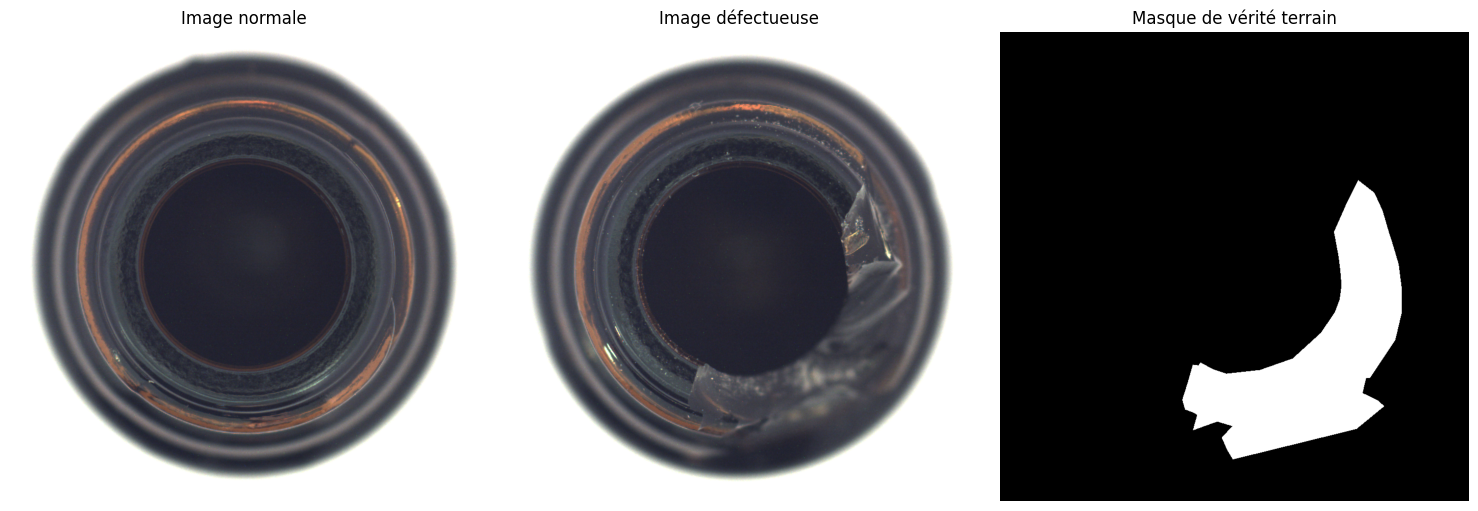

Dimensions normales:  (900, 900, 3)
Dimensions défaut:  (900, 900, 3)
Dimensions masque:  (900, 900)


In [ ]:
from pathlib import Path
import cv2
import matplotlib.pyplot as plt

assert (BOTTLE_DIR / "train" / "good").exists(), "Dataset bottle introuvable"

print("Dataset utilisé: ", BOTTLE_DIR)

# Choix des images
normal_path = sorted((BOTTLE_DIR / "train" / "good").glob("*.png"))[0]

defect_path = sorted((BOTTLE_DIR / "test" / "broken_large").glob("*.png"))[0]

mask_path = BOTTLE_DIR / "ground_truth" / "broken_large" / f"{defect_path.stem}_mask.png"


assert mask_path.exists(), f"Masque introuvable: {mask_path}"

# Chargement des images
normal = cv2.cvtColor(cv2.imread(str(normal_path)), cv2.COLOR_BGR2RGB)

defect = cv2.cvtColor(cv2.imread(str(defect_path)), cv2.COLOR_BGR2RGB)

mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
assert mask is not None, f"Masque illisible : {mask_path}"

# Affichage
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(normal)
axes[0].set_title("Image normale")

axes[1].imshow(defect)
axes[1].set_title("Image défectueuse")

if mask.ndim == 2:
    axes[2].imshow(mask, cmap="gray")
else:
    axes[2].imshow(mask)

axes[2].set_title("Masque de vérité terrain")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Dimensions normales: ", normal.shape)
print("Dimensions défaut: ", defect.shape)
print("Dimensions masque: ", mask.shape)

***1.3 - Prétraitement des images & des masques***

Redimensionnement à 256 × 256 pixels, normalisation RGB et binarisation des annotations

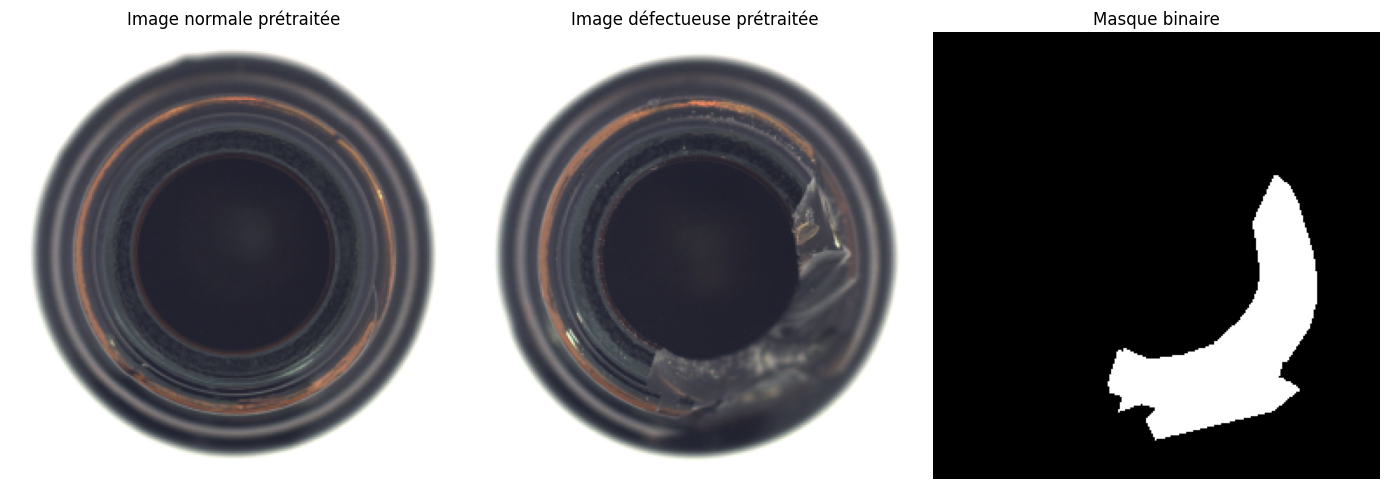

Dimensions image:  (256, 256, 3)
Dimensions masque:  (256, 256)
Valeurs du masque:  [0 1]
Pixels anormaux:  7130


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

DISPLAY_SIZE = (256, 256)

# Redimensionnement des images RGB
normal_resized = cv2.resize(normal, DISPLAY_SIZE, interpolation=cv2.INTER_AREA)
defect_resized = cv2.resize(defect, DISPLAY_SIZE, interpolation=cv2.INTER_AREA)

# Conversion en valeurs flottantes normalisées
normal_processed = normal_resized.astype(np.float32) / 255.0
defect_processed = defect_resized.astype(np.float32) / 255.0

# Conversion du masque en un seul canal
if mask.ndim == 3:
    mask_gray = cv2.cvtColor(mask, cv2.COLOR_BGRA2GRAY) if mask.shape[2] == 4 else cv2.cvtColor(mask, cv2.COLOR_BGR2GRAY)
else:
    mask_gray = mask

# NEAREST_NEIGHBOR préserve les étiquettes du masque
mask_resized = cv2.resize(mask_gray, DISPLAY_SIZE, interpolation=cv2.INTER_NEAREST)

mask_binary = (mask_resized > 0).astype(np.uint8)

# Visualisation
fig, axes = plt.subplots(1, 3, figsize=(14, 5))

axes[0].imshow(normal_processed)
axes[0].set_title("Image normale prétraitée")

axes[1].imshow(defect_processed)
axes[1].set_title("Image défectueuse prétraitée")

axes[2].imshow(mask_binary, cmap="gray", vmin=0, vmax=1)
axes[2].set_title("Masque binaire")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Dimensions image: ", normal_processed.shape)
print("Dimensions masque: ", mask_binary.shape)
print("Valeurs du masque: ", np.unique(mask_binary))
print("Pixels anormaux: ", np.count_nonzero(mask_binary))

# ***2. Détection classique d'anomalies — OpenCV***

Cette section présente notre première approche de détection d'anomalies industrielles, basée sur la comparaison d'une image avec une référence normale.

**Pipeline :**
1. Construction d'une image moyenne de référence.
2. Calcul des différences pixel par pixel.
3. Génération d'une carte d'anomalie.
4. Segmentation et localisation des défauts.

**Remarque :** la référence et les seuils officiels sont déjà restaurés par la section 0. Les premières cellules sont pédagogiques et n'écrasent pas ces paramètres.

***2.1 — Construction de l'image moyenne de référence***

Cette cellule illustre la construction d'une image moyenne de référence à partir des **209 images normales** du dossier `train` de MVTec AD `bottle`.

Cette référence est utilisée uniquement à des fins pédagogiques, afin de comprendre le principe de la détection d'anomalies par comparaison avec une image normale représentative.

**Distinction importante :**

Deux références sont utilisées dans le notebook :

- **`reference_image_demo`** : calculée à partir des 209 images normales, uniquement pour les démonstrations de la section 2.
- **`reference_image`** : référence officielle calculée à partir des 167 images normales réservées à l'entraînement. Les 42 autres images servent à la validation et à la calibration des seuils.

Cette séparation évite d'utiliser les images de validation pour construire la référence officielle.

La référence pédagogique ne remplace jamais la référence officielle utilisée dans les évaluations de la section 5.


Nombre d'images normales:  209
Temps de calcul : 6.16 s


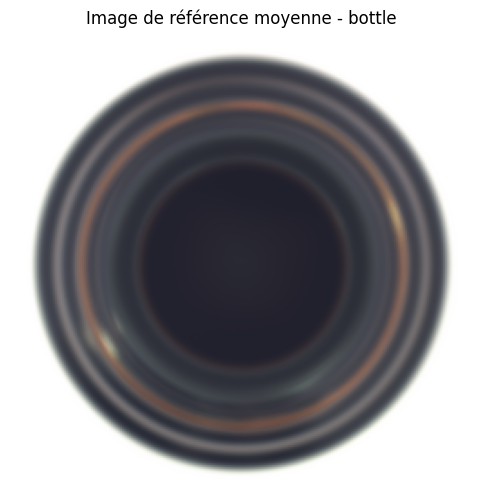

Dimensions :  (256, 256, 3)
Valeurs min/max:  0.12434562 1.0

✅ La référence restaurée `reference_image` n'a pas été modifiée.


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import time

# Répertoire contenant uniquement les images normales
train_dir = BOTTLE_DIR / "train" / "good"
image_paths = sorted(train_dir.glob("*.png"))

print("Nombre d'images normales: ", len(image_paths))
assert len(image_paths) > 0, "Aucune image normale trouvée"

start = time.time()

# Accumulateur pour la somme des images
image_sum = np.zeros((256, 256, 3), dtype=np.float64)

for path in image_paths:
    image = cv2.imread(str(path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Redimensionnement
    image = cv2.resize(image, (256, 256), interpolation=cv2.INTER_AREA)

    # Conversion en valeurs flottantes normalisées
    image = image.astype(np.float64) / 255.0

    # Addition des valeurs pixel à pixel
    image_sum += image

# Calcul de la moyenne
reference_image_demo = (image_sum / len(image_paths)).astype(np.float32)


print(f"Temps de calcul : {time.time() - start:.2f} s")

# Visualisation
plt.figure(figsize=(6, 6))
plt.imshow(reference_image_demo)
plt.axis("off")
plt.title("Image de référence moyenne - bottle")
plt.show()

print("Dimensions : ", reference_image_demo.shape)
print(
    "Valeurs min/max: ",
    reference_image_demo.min(), reference_image_demo.max()
)

if "reference_image" in globals():
    print("\n✅ La référence restaurée `reference_image` n'a pas été modifiée.")

***2.2 - Génération d'une carte d'anomalie***

Calcul des différences pixel par pixel entre une image défectueuse et la référence moyenne

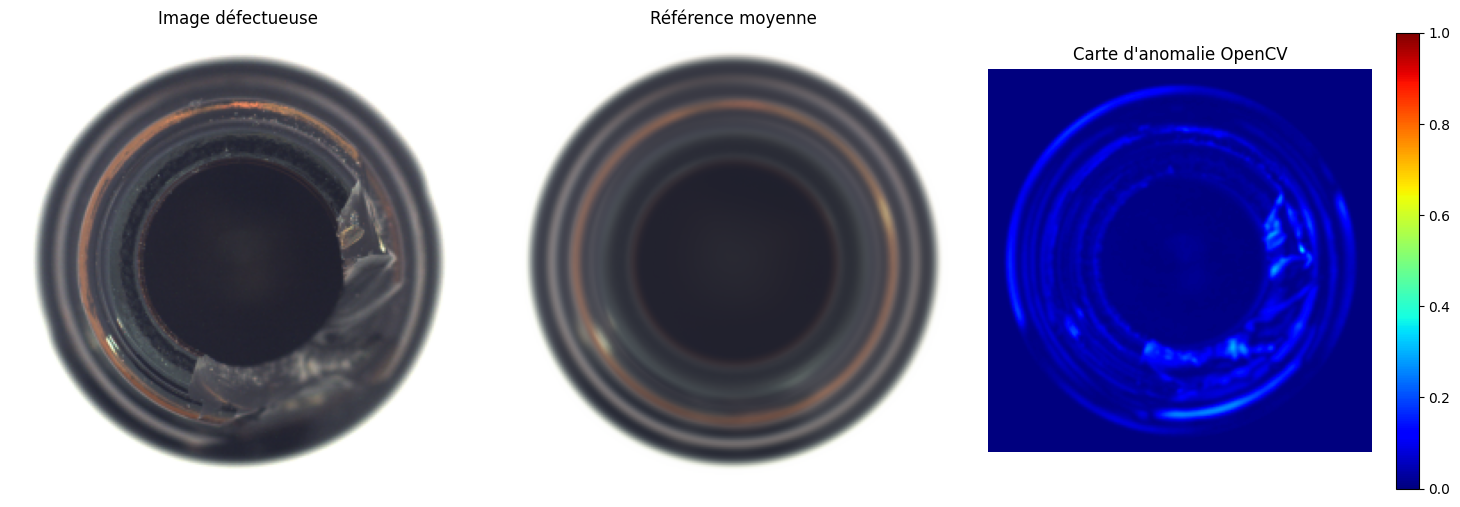

Dimensions carte:  (256, 256)
Score maximal:  0.35547516
Score minimal:  0.0

✅ La référence restaurée `reference_image` n'a pas été modifiée.


In [ ]:
# Différence absolue entre l'image test & la référence
difference = cv2.absdiff(defect_processed, reference_image_demo)

# Moyenne des différences sur les canaux RGB
anomaly_map_cv_demo = np.mean(difference, axis=2)

# Lissage gaussien pour réduire le bruit
anomaly_map_cv_demo = cv2.GaussianBlur(anomaly_map_cv_demo, (5, 5), 0)

# Visualisation
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(defect_processed)
axes[0].set_title("Image défectueuse")

axes[1].imshow(reference_image_demo)
axes[1].set_title("Référence moyenne")

im = axes[2].imshow(anomaly_map_cv_demo, cmap="jet", vmin = 0, vmax = 1)
axes[2].set_title("Carte d'anomalie OpenCV")

plt.colorbar(im, ax=axes[2])

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Dimensions carte: ", anomaly_map_cv_demo.shape)
print("Score maximal: ", anomaly_map_cv_demo.max())
print("Score minimal: ", anomaly_map_cv_demo.min())

if "reference_image" in globals():
    print("\n✅ La référence restaurée `reference_image` n'a pas été modifiée.")

***2.3 - Segmentation & localisation des défauts***

Application d'un seuil calibré, extraction des régions suspectes et localisation des défauts par contours

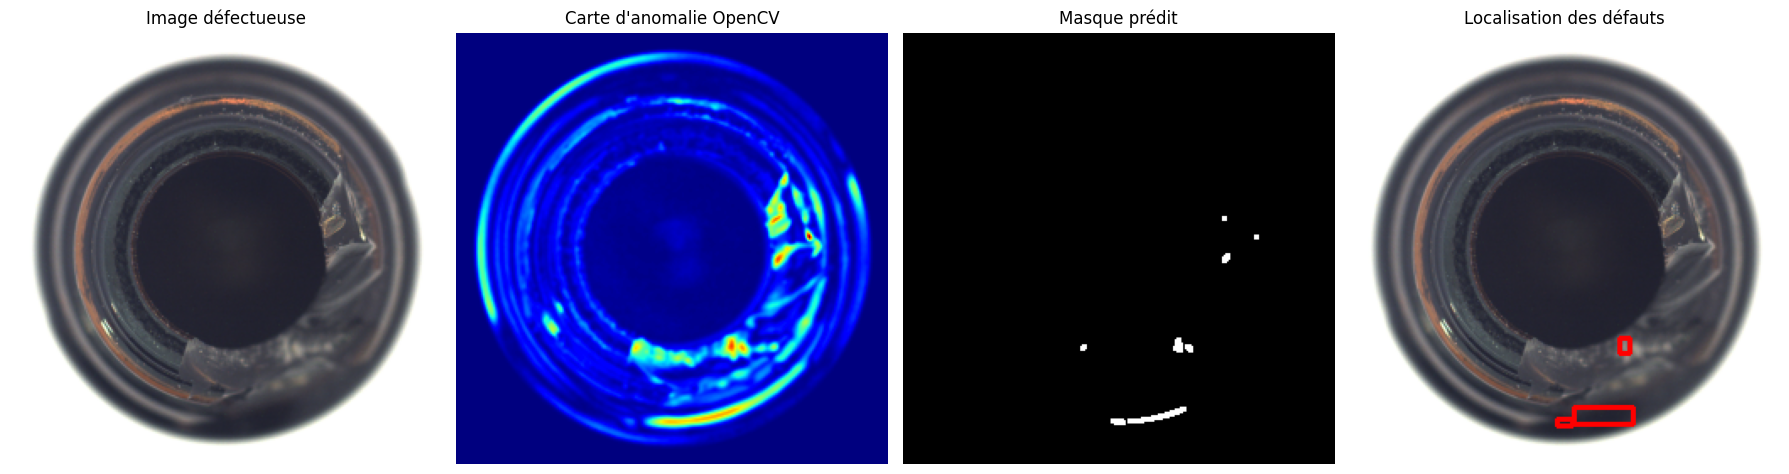

Seuil pixel : 0.207408
Pixels prédits anormaux : 276
Pixels réellement anormaux : 7130
IOU sur cette image : 0.0292


In [ ]:
import matplotlib.pyplot as plt
import cv2
import numpy as np

# Recalcul aveec la référence issue de la cellule précédente
difference = cv2.absdiff(defect_processed, reference_image)

anomaly_map_cv = np.mean(difference, axis=2)
anomaly_map_cv = cv2.GaussianBlur(anomaly_map_cv, (5, 5), 0)

# Masque binaire prédit
predicted_mask = (anomaly_map_cv > pixel_threshold).astype(np.uint8)

# Suppression des petites régions isolées
kernel = np.ones((3, 3), np.uint8)
predicted_mask = cv2.morphologyEx(predicted_mask, cv2.MORPH_OPEN, kernel)

# Localisation par contours
contours, _ = cv2.findContours(predicted_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

localized_image = (defect_processed * 255).astype(np.uint8)

MIN_CONTOUR_AREA = 20       # Taille minimale d'une région à encadrer

for contour in contours:
    # Ignorer les régions trop petites
    if cv2.contourArea(contour) < MIN_CONTOUR_AREA:
        continue

    # Calcul du rectangle englobant & dessin de ce rectangle autour de la région
    x, y, w, h = cv2.boundingRect(contour)
    cv2.rectangle(
        localized_image, (x, y), (x + w, y + h),
        (255, 0, 0), 2
    )

# Affichage
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

axes[0].imshow(defect_processed)
axes[0].set_title("Image défectueuse")

axes[1].imshow(anomaly_map_cv, cmap="jet")
axes[1].set_title("Carte d'anomalie OpenCV")

axes[2].imshow(predicted_mask, cmap="gray", vmin=0, vmax=1)
axes[2].set_title("Masque prédit")

axes[3].imshow(localized_image)
axes[3].set_title("Localisation des défauts")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

# Comparaison avec la vérité terrain
intersection = np.logical_and(predicted_mask, mask_binary).sum()
union = np.logical_or(predicted_mask, mask_binary).sum()

iou = intersection / union if union > 0 else 1.0

print(f"Seuil pixel : {pixel_threshold:.6f}")
print(f"Pixels prédits anormaux : {predicted_mask.sum()}")
print(f"Pixels réellement anormaux : {mask_binary.sum()}")
print(f"IOU sur cette image : {iou:.4f}")

***2.4 — Bilan de la méthode OpenCV***

La méthode classique repose sur une comparaison pixel par pixel entre l'image testée et une référence normale.

**Avantages :**
- Implémentation simple et rapide.
- Aucun entraînement neuronal nécessaire.
- Cartes d'anomalies facilement interprétables.

**Limites :**
- Sensibilité aux variations d'éclairage et de position.
- Détection parasite des contours normaux.
- Difficultés à segmenter entièrement les défauts.

La méthode constitue notre **baseline expérimentale**, à laquelle nous comparerons les approches CNN dans la section d'évaluation.

# ***3. Détection d'anomalies par autoencodeur CNN***

Cette section présente une approche de détection d'anomalies fondée sur l'apprentissage des caractéristiques des images normales.

**Principe :**

L'autoencodeur apprend à reconstruire des images industrielles normales. Lorsqu'une image défectueuse lui est présentée, les différences entre l'image originale et sa reconstruction peuvent révéler les anomalies.

**Étapes :**
1. Préparation des données PyTorch.
2. Définition de l'architecture de l'autoencodeur.
3. Entraînement sur les images normales.
4. Sauvegarde des poids du modèle.
5. Reconstruction et analyse des erreurs.

**Remarque :** le modèle préentraîné est automatiquement restauré par la section 0. Il n'est pas nécessaire de relancer son entraînement à chaque connexion.

***3.1 - Préparation des données PyTorch***

Création des jeux d'entraînement et de validation ainsi que des DataLoaders

In [ ]:
import torch
import cv2
import numpy as np

from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split

# Config
IMG_SIZE = 256
BATCH_SIZE = 16
SEED = 42

torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Périphérique utilisé : ", device)

# Dataset PyTorch
class MVTecNormalDataset(Dataset):
    def __init__(self, paths):
        self.paths = list(paths)

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        path = self.paths[idx]
        image = cv2.imread(str(path))
        if image is None:
            raise RuntimeError(f"Image illisible : {path}")

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image = cv2.resize(image, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
        image = image.astype(np.float32) / 255.0

        # HWC -> CHW
        image = torch.from_numpy(
            image.transpose(2, 0, 1).copy()
        )

        return image

# Reprise du même découpage que la baseline OpenCV
image_paths = sorted(
    (BOTTLE_DIR / "train" / "good").glob("*.png")
)

train_paths, val_paths = train_test_split(
    image_paths, test_size=0.2, random_state=SEED, shuffle=True
)

train_dataset = MVTecNormalDataset(train_paths)
val_dataset = MVTecNormalDataset(val_paths)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=2, pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=2, pin_memory=(device.type == "cuda")
)

# Vérification
batch = next(iter(train_loader))

print("Images entraînement: ", len(train_dataset))
print("Images validation: ", len(val_dataset))
print("Dimensions d'un batch: ", batch.shape)
print("Type: ", batch.dtype)
print("Valeurs min/max: ", batch.min().item(), batch.max().item())

Périphérique utilisé :  cuda
Images entraînement:  167
Images validation:  42
Dimensions d'un batch:  torch.Size([16, 3, 256, 256])
Type:  torch.float32
Valeurs min/max:  0.10980392247438431 1.0


***3.2 — Architecture et vérification de l'autoencodeur CNN***

L'autoencodeur convolutif utilisé dans ce projet est défini et restauré dans la cellule **0.4**.

Son architecture comprend :

- **Encodeur** : quatre couches convolutives successives réduisant progressivement les dimensions spatiales et augmentant le nombre de canaux.
- **Espace latent** : représentation compressée de l'image.
- **Décodeur** : quatre couches de convolution transposée permettant de reconstruire une image de mêmes dimensions que l'entrée.
- **Activation finale Sigmoid** : production de valeurs comprises entre 0 et 1.

Cette cellule vérifie :

1. La disponibilité du modèle restauré.
2. La cohérence de son architecture.
3. Le nombre de paramètres.
4. Les dimensions des tenseurs d'entrée et de sortie.
5. Son état d'évaluation.

**Aucun modèle n'est recréé et aucun poids n'est réinitialisé.**


In [ ]:
import torch

# ===========================================================
# 1. Vérification du modèle restauré
# ===========================================================
assert "model" in globals(), "Modèle absent : exécuter la cellule 0.4"
assert "ConvAutoencoder" in globals(), "Architecture absente: exécuter la classe 0.4"
assert isinstance(model, ConvAutoencoder), (
    "Le modèle et la classe ne correspondent pas: exécuter la classe 0.4"
)
assert not model.training, "Le modèle doit passer en mode évaluation"

# ===========================================================
# 2. Présentation de l'architecture
# ===========================================================
print("=== ARCHITECTURE DE L'AUTOENCODEUR ===")

print("\nEncodeur :")
print(model.encoder)

print("\nDécodeur :")
print(model.decoder)

# ==========================================================
# 3. Nombre de paramètres
# ==========================================================
total_parameters = sum(p.numel() for p in model.parameters())
print(f"\nNombre total de paramètres : {total_parameters}")

assert total_parameters == 1_078_307, "L'architecture ne correspond pas au CNN attendu."

# ==========================================================
# 4. Vérification des dimensions
# ==========================================================
test_input = torch.zeros((1, 3, 256, 256), device=device)

with torch.inference_mode():
    test_output = model(test_input)

assert test_output.shape == test_input.shape, "Dimensions de reconstruction incorrectes."

print("\nEntrée :", tuple(test_input.shape))
print("Sortie :", tuple(test_output.shape))

# ==========================================================
# 5. Validation finale
# ==========================================================
print("\nPériphérique :", next(model.parameters()).device)
print("Mode évaluation :", not model.training)

print("\n✅ Architecture CNN vérifiée.")
print("✅ Aucun modèle réinitialisé.")
print("✅ Aucun entraînement effectué.")

=== ARCHITECTURE DE L'AUTOENCODEUR ===

Encodeur :
Sequential(
  (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
  (1): ReLU(inplace=True)
  (2): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
  (3): ReLU(inplace=True)
  (4): Conv2d(64, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
  (5): ReLU(inplace=True)
  (6): Conv2d(128, 256, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
  (7): ReLU(inplace=True)
)

Décodeur :
Sequential(
  (0): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
  (1): ReLU(inplace=True)
  (2): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
  (3): ReLU(inplace=True)
  (4): ConvTranspose2d(64, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
  (5): ReLU(inplace=True)
  (6): ConvTranspose2d(32, 3, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
  (7): Sigmoid()
)

Nombre total de paramètres : 1078307

Entrée : (1, 3, 256, 256)
Sortie : (1, 3, 256, 

***3.3 — Entraînement sécurisé de l'autoencodeur CNN***

**Entraînement facultatif — Désactivé par défaut**

Cette cellule permet d'entraîner un nouvel autoencodeur convolutif sans modifier les poids du modèle de référence restauré en 0.4.

Deux objets distincts sont utilisés :

- `model` : autoencodeur de référence, déjà entraîné et utilisé pour l'inférence.
- `training_model` : nouvel autoencodeur initialisé pour une expérience d'entraînement.

L'entraînement est contrôlé par `RUN_TRAINING` :

- `False` : aucune opération d'entraînement.
- `True` : création et entraînement d'un nouveau modèle.

Le meilleur modèle de chaque expérience est enregistré sous un nom distinct dans le stockage local de Colab.

La copie permanente vers Google Drive sera gérée par la cellule 3.4.

**Important :** entraîner un nouveau modèle nécessitera ensuite de recalibrer ses seuils de détection et de segmentation. Les paramètres CNN V1/V2/V3 actuels restent associés au modèle de référence.


In [ ]:
import time
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from datetime import datetime

# Indique si cette exécution a produit un nouveau modèle
TRAINING_RESULT_READY = False
if RUN_TRAINING:

    assert MODE == "experimentation", "Sélectionner le mode expérimentation"
    assert "ConvAutoencoder" in globals()
    assert "train_loader" in globals(), "Pas de jeu d'entraînement"
    assert "val_loader" in globals(), "Pas de jeu de validation"

    # ====================================================
    # 1. Paramètres de l'expérience
    # ====================================================

    EPOCHS = 30
    LEARNING_RATE = 1e-3

    torch.manual_seed(SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    # ====================================================
    # 2. Nouveau modèle indépendant
    # ====================================================
    training_model = ConvAutoencoder().to(device)
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(
        training_model.parameters(), lr=LEARNING_RATE
    )

    # ===================================================
    # 3. Chemin de sauvegarde unique
    # ===================================================
    training_dir = PROJECT_DIR / "outputs" / "models"
    training_dir.mkdir(parents=True, exist_ok=True)
    training_run_id = datetime.now().strftime("%Y%m%d_%H%M%S")
    training_model_path = training_dir / f"autoencoder_bottle_candidate_{training_run_id}.pth"

    assert not training_model_path.exists(), "Un fichier porte déjà ce nom."

    # ===================================================
    # 4. Historique des pertes
    # ===================================================
    train_losses = []
    val_losses =[]

    best_val_loss = float("inf")

    start = time.perf_counter()

    # ===================================================
    # 5. Entraînement
    # ===================================================
    for epoch in range(EPOCHS):
        training_model.train()
        train_loss_sum = 0.0

        for images in train_loader:
            images = images.to(device)

            optimizer.zero_grad()

            reconstructed = training_model(images)
            loss = criterion(reconstructed, images)

            loss.backward()
            optimizer.step()

            train_loss_sum += loss.item() * images.size(0)


        train_loss = train_loss_sum / len(train_dataset)

        # ===============================================
        # 6. Validation
        # ===============================================
        training_model.eval()
        val_loss_sum = 0.0

        with torch.inference_mode():
            for images in val_loader:
                images = images.to(device)
                reconstructed = training_model(images)
                loss = criterion(reconstructed, images)

                val_loss_sum += loss.item() * images.size(0)

        val_loss = val_loss_sum / len(val_dataset)

        train_losses.append(train_loss)
        val_losses.append(val_loss)

        # ==============================================
        # 7. Meilleurs poids
        # ==============================================
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(training_model.state_dict(), training_model_path)

        print(
            f"Epoch {epoch+1:02d}/{EPOCHS} | "
            f"Train loss: {train_loss:.6f} | "
            f"Validation loss: {val_loss:.4f}"
        )

    # ==================================================
    # 8. Bilan
    # ==================================================
    elapsed = time.perf_counter() - start

    assert training_model_path.is_file(), "Aucun modèle candidat sauvegardé"
    TRAINING_RESULT_READY = True

    print("\n=== ENTRAÎNEMENT  TERMINÉ")
    print(f"Durée : {elapsed:.2f} s")
    print(f"Meilleure loss validation : {best_val_loss:.6f}")
    print(f"Modèle candidat : {training_model_path}")

    # Courbes des pertes
    plt.figure(figsize=(9, 5))
    plt.plot(train_losses, label="Entraînement")
    plt.plot(val_losses, label="Validation")

    plt.xlabel("Époque")
    plt.ylabel("MSE")
    plt.title("Entraînement de l'autoencodeur CNN")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

    # Contrôle du modèle de référence préservé
    assert not model.training

    print("\nModèle de référence préservé.")

else:
    print("=== ENTRAÏNEMENT DÉSACTIVÉ ===")
    print("Aucun nouvel autoencodeur créé.")
    print("Aucun poids modifié.")
    print("Modèle de référence conservé.")

=== ENTRAÏNEMENT DÉSACTIVÉ ===
Aucun nouvel autoencodeur créé.
Aucun poids modifié.
Modèle de référence conservé.


***3.4 — Sauvegarde sécurisée des modèles expérimentaux***

Le modèle de référence `autoencoder_bottle_best.pth` est conservé sur Google Drive et ne doit jamais être écrasé par un nouvel entraînement.

Lorsqu'une expérience d'entraînement est terminée, cette cellule copie le modèle candidat depuis le stockage temporaire de Colab vers le dossier permanent `models/candidates/` de Google Drive.

La sauvegarde est effectuée uniquement si :
- `RUN_TRAINING` vaut `True`.
- L'entraînement s'est terminé correctement.
- Le fichier candidat existe.
- Aucun fichier de même nom n'est déjà présent sur Drive.

Si l'entraînement est désactivé, aucune copie n'est réalisée.


In [ ]:
from pathlib import Path
import shutil


# Vérification du stockage permanent
assert "DRIVE_PROJECT" in globals()
assert "RUN_TRAINING" in globals()

reference_path = DRIVE_PROJECT / "models/autoencoder_bottle_best.pth"
assert reference_path.exists(), "Modèle de référence introuvable sur Google Drive"

if not RUN_TRAINING:
    print("=== SAUVEGARDE NON NECESSAIRE ===")
    print("Entraînement désactivé.")
    print("Modèle de référence :", reference_path.name)
    print("Aucun fichier modifié.")
else:
    # Un entraînement doit avoir été achevé
    assert globals().get("TRAINING_RESULT_READY", False), "Aucun entraînement terminé à sauvegarder"
    assert "training_model_path" in globals()

    source = Path(training_model_path)
    assert source.is_file(), f"Modèle candidat introuvable : {source}"

    # Dossier permanent des modèles candidats
    destination_dir = DRIVE_PROJECT / "models" / "candidates"
    destination_dir.mkdir(parents=True, exist_ok=True)

    destination = destination_dir / source.name
    assert not destination.exists(), f"Fichier déjà présent : {destination}"

    # Copie du modèle entraîné sur Drive
    shutil.copy2(source, destination)

    # Vérification de la copie
    assert destination.is_file()
    assert destination.stat().st_size == source.stat().st_size

    print("\n=== MODÈLE CANDIDAT SAUVEGARDÉ ===")
    print(f"Source : {source}")
    print(f"Destination : {destination}")
    print("Taille :", round(destination.stat().st_size / 1024**2, 2), "Mo")

print("\nModèle de référence préservé.")

=== SAUVEGARDE NON NECESSAIRE ===
Entraînement désactivé.
Modèle de référence : autoencoder_bottle_best.pth
Aucun fichier modifié.

Modèle de référence préservé.


***3.5 - Reconstruction & analyse des erreurs***

Reconstruction d'une image défectueuse et calcul de l'erreur entre l'image originale et sa reconstruction

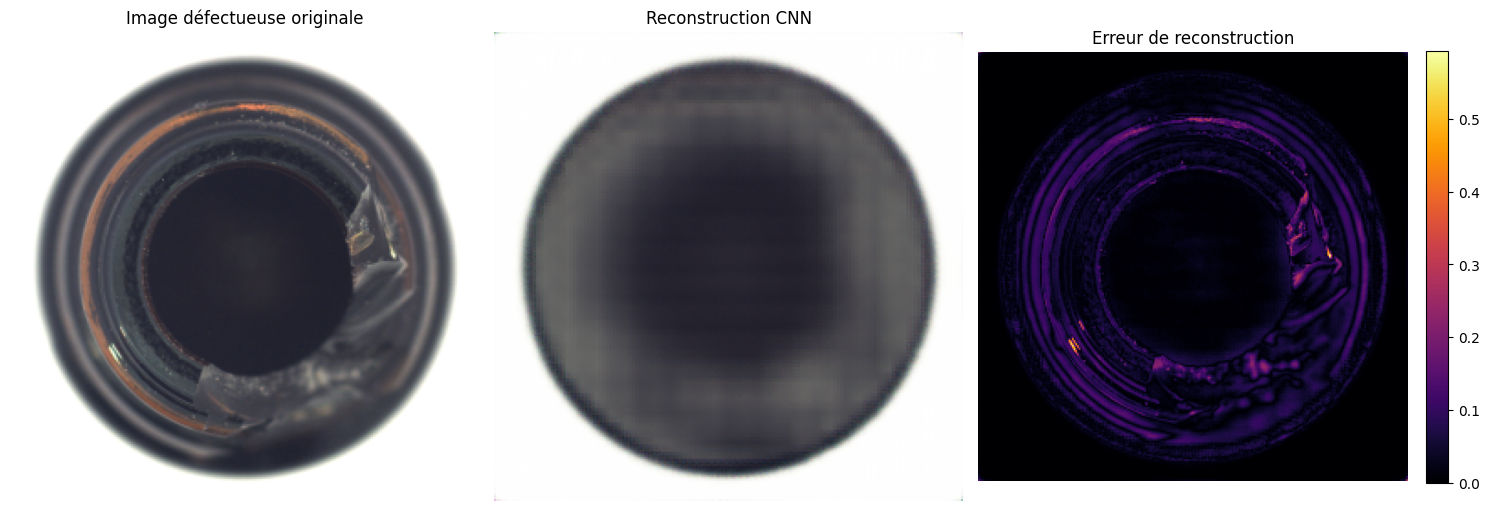

Dimensions reconstruction :  (256, 256, 3)
Erreur moyenne :  0.027429901
Erreur maximale :  0.5940687


In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt

# Charger les meilleurs poids sauvegardés
model.eval()

# Conversion de l'image défectueuse en tenseur PyTorch
input_tensor = torch.from_numpy(defect_processed.transpose(2, 0, 1).copy()).unsqueeze(0).to(device)

# Inférence
with torch.no_grad():
    output_tensor = model(input_tensor)

# Conversion au format NumPy (H, W, C)
reconstruction = (output_tensor.squeeze(0).cpu().numpy().transpose(1, 2, 0))

# Erreur de reconstruction par pixel
reconstruction_error = np.mean(np.abs(defect_processed - reconstruction), axis=2)

# Affichage
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(defect_processed)
axes[0].set_title("Image défectueuse originale")

axes[1].imshow(reconstruction)
axes[1].set_title("Reconstruction CNN")

im = axes[2].imshow(reconstruction_error, cmap="inferno")
axes[2].set_title("Erreur de reconstruction")

for ax in axes:
    ax.axis("off")

fig.colorbar(im, ax=axes[2], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

print("Dimensions reconstruction : ", reconstruction.shape)
print("Erreur moyenne : ", reconstruction_error.mean())
print("Erreur maximale : ", reconstruction_error.max())

***3.6 — Bilan de l'autoencodeur CNN***

L'autoencodeur convolutif a été entraîné exclusivement sur des images normales de la catégorie `bottle` du dataset MVTec AD.

**Configuration :**
- Framework : PyTorch.
- GPU : NVIDIA Tesla T4.
- Résolution : 256 × 256 pixels.
- Architecture : encodeur-décodeur convolutif.
- Fonction de perte : MSE.
- Entraînement : 30 époques.

**Observations :**

Le réseau apprend à reconstruire les images normales, mais certaines structures et textures produisent des erreurs de reconstruction importantes, même en l'absence de défaut.

De plus, certaines anomalies sont partiellement reconstruites par le réseau, ce qui limite leur détection.

**Conclusion :**

L'erreur de reconstruction brute ne suffit pas à garantir une bonne localisation des défauts.

Nous étudierons donc plusieurs méthodes de traitement de cette erreur dans la section suivante, sans modifier les poids du réseau.

# ***4. Méthodes de détection d'anomalies — CNN V1, V2 et V3***

Cette section compare trois méthodes de génération de cartes d'anomalies à partir d'un autoencodeur CNN unique.

**Méthodes étudiées :**

- **CNN V1 :** erreur absolue moyenne entre l'image originale et sa reconstruction.
- **CNN V2 :** normalisation spatiale des erreurs en fonction des statistiques observées sur des images normales.
- **CNN V3 :** lissage gaussien des cartes normalisées pour améliorer la continuité des régions détectées.

Les trois versions partagent les mêmes poids CNN.

**Objectif :** centraliser la génération des cartes et masques d'anomalies, sans dupliquer le code d'inférence.

**Mode requis :** `experimentation`.

Les seuils et statistiques sont restaurés depuis Google Drive par la section 0.

***4.1 — Génération des cartes d'anomalies CNN***

Implémentation d'une fonction commune pour calculer les cartes d'anomalies des versions V1, V2 et V3.

**Traitements :**
1. Chargement et normalisation de l'image.
2. Reconstruction avec l'autoencodeur préentraîné.
3. Calcul de l'erreur de reconstruction V1.
4. Normalisation spatiale pour la V2.
5. Lissage gaussien pour la V3.

Aucun entraînement ni changement des paramètres.

In [ ]:
import cv2
import numpy as np
import torch

assert MODE == "experimentation", "Sélectionner le mode expérimentation"

# 1. Chargement & prétraitement
def load_image(path):

    image = cv2.imread(str(path))
    assert image is not None, f"Image illisible : {path}"

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(image, (256, 256),interpolation=cv2.INTER_AREA)

    return image.astype(np.float32) / 255.0

# 2. Génération des cartes CNN
def generate_cnn_maps(image):

    assert image.shape == (256, 256, 3)

    model.eval()

    # Conversion NumPy -> PyTorch
    tensor = torch.from_numpy(image.transpose(2, 0, 1).copy()).unsqueeze(0).to(device)

    # Reconstruction par le CNN
    with torch.inference_mode():
        reconstruction = model(tensor)
        error = torch.abs(tensor - reconstruction).mean(dim=1).squeeze(0).cpu().numpy()

    # V1 : erreur de reconstruction
    map_v1 = cv2.GaussianBlur(error, (5, 5), 0)

    # V2 : normalisation spatiale
    map_v2 = np.maximum((map_v1 - cnn_mean_map_v2) / np.maximum(cnn_std_map_v2, EPSILON_V2), 0)

    # V3 : lissage gaussien de la V2
    map_v3 = cv2.GaussianBlur(map_v2, (0, 0), sigmaX=cnn_sigma_v3)

    return {"V1": map_v1, "V2": map_v2,"V3": map_v3}

print("Fonctions de chargement & de génération disponibles.")

Fonctions de chargement & de génération disponibles.


***4.2 — Segmentation des anomalies CNN***

Application des seuils calibrés propres à chaque version CNN.

Les masques binaires sont nettoyés par ouverture morphologique pour supprimer les petites régions isolées.

**Sortie :** un masque binaire par version (V1, V2 et V3).

In [ ]:
import numpy as np
import cv2


def generate_cnn_masks(anomaly_maps):

    # Seuils de segmentation restaurés
    thresholds = {
        "V1": cnn_pixel_threshold,
        "V2": cnn_pixel_threshold_v2,
        "V3": cnn_pixel_threshold_v3
    }

    masks = {}
    kernel = np.ones((3, 3), dtype=np.uint8)

    for version, map in anomaly_maps.items():

        threshold = thresholds[version]

        # Seuillage
        mask = (map > threshold).astype(np.uint8)

        # Nettoyage morphologique
        mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)

        masks[version] = mask

    return masks

print("Fonction de segmentation disponible.")

Fonction de segmentation disponible.


***4.3 — Vérification des méthodes CNN V1, V2 et V3***

Test du pipeline commun sur une image défectueuse MVTec AD.

Vérification des dimensions des cartes et masques, ainsi que du nombre de pixels suspects détectés par chaque méthode.

In [ ]:
# Sélection reproductible d'une image défectueuse
test_path = sorted((BOTTLE_DIR / "test/broken_large").glob("*.png"))[0]

# Chargement
image = load_image(test_path)

# Génération des cartes
anomaly_maps = generate_cnn_maps(image)

# Génération des masques
anomaly_masks = generate_cnn_masks(anomaly_maps)

print("=== VERIFICATION DES METHODES CNN ===")

for version in ["V1", "V2", "V3"]:

    anomaly_map = anomaly_maps[version]
    mask = anomaly_masks[version]

    assert anomaly_map.shape == (256, 256)
    assert mask.shape == (256, 256)
    assert set(np.unique(mask)).issubset({0, 1})

    print(f"\nCNN {version}")
    print("Dimensions carte :", anomaly_map.shape)
    print("Dimensions masque :", mask.shape)
    print("Score maximal :", round(float(anomaly_map.max()), 6))
    print("Pixels suspects :", int(mask.sum()))

=== VERIFICATION DES METHODES CNN ===

CNN V1
Dimensions carte : (256, 256)
Dimensions masque : (256, 256)
Score maximal : 0.331932
Pixels suspects : 270

CNN V2
Dimensions carte : (256, 256)
Dimensions masque : (256, 256)
Score maximal : 14.191208
Pixels suspects : 1041

CNN V3
Dimensions carte : (256, 256)
Dimensions masque : (256, 256)
Score maximal : 7.050241
Pixels suspects : 1958


# ***5. Évaluation comparative des méthodes de détection***

Cette section présente une évaluation homogène des quatre approches développées sur le dataset MVTec AD `bottle`.

**Méthodes comparées :**
- OpenCV — Différence avec une référence moyenne.
- CNN V1 — Erreur de reconstruction RGB.
- CNN V2 — Normalisation spatiale des erreurs.
- CNN V3 — Normalisation spatiale et lissage gaussien.

**Métriques :**
- Classification : AUROC, précision, rappel et F1-score.
- Segmentation : Pixel AUROC, précision, rappel et IoU.

Les évaluations utilisent les mêmes 83 images de test et les mêmes annotations.

**Limite méthodologique :** les images de test ont déjà servi à plusieurs diagnostics. Les résultats de comparaison sont donc exploratoires et ne constituent pas une validation finale indépendante.

***5.1 — Vérification et recalibrage sécurisé des seuils CNN V3***

**Mode expérimentation — Recalibrage facultatif**

Cette cellule vérifie la configuration CNN V3 restaurée en 0.7.

Par défaut, `RUN_V3_RECALIBRATION = False` :

- Les paramètres sauvegardés sont contrôlés.
- Aucune inférence CNN n'est exécutée.
- Aucun seuil n'est recalculé.
- Aucun fichier n'est modifié.

Lorsque `RUN_V3_RECALIBRATION = True`, une nouvelle calibration est réalisée à partir de 21 images normales de validation.

Les nouveaux paramètres sont enregistrés dans `checkpoints/candidates/`, sans remplacer la configuration officielle.

Toute adoption d'une nouvelle configuration nécessitera une validation distincte.


In [ ]:
import numpy as np
from datetime import datetime

assert MODE == "experimentation", "Sélectionner le mode expérimentation"
# assert len(val_paths) == 42

# Recalibrage désactivé par défaut
RUN_V3_RECALIBRATION = False

# ========================================================
# 1. Configuration officielle
# ========================================================
v3_path = DRIVE_PROJECT / "checkpoints/cnn_bottle_smoothing_v3.npz"
assert v3_path.is_file(), "Configuration CNN V3 introuvable sur Drive."

# ========================================================
# 2. Vérification des paramètres restaurés
# ========================================================
with np.load(v3_path, allow_pickle=False) as saved:
    saved_sigma = float(saved["sigma"])
    saved_pixel_threshold = float(saved["pixel_threshold"])
    saved_image_threshold = float(saved["image_threshold"])

assert np.isclose(saved_sigma, cnn_sigma_v3)
assert np.isclose(saved_pixel_threshold, cnn_pixel_threshold_v3)
assert np.isclose(saved_image_threshold, cnn_image_threshold_v3)

print("\n=== CONFIGURATION CNN V3 ===")
print(f"Sigma : {saved_sigma:.6f}")
print(f"Seuil image : {saved_image_threshold:.6f}")
print(f"Seuil pixel : {saved_pixel_threshold:.6f}")

print("\nConfiguration restaurée cohérente.")

# =====================================================
# 3. Recalibrage facultatif
# =====================================================
if RUN_V3_RECALIBRATION:
    assert len(val_paths) == 42
    assert "generate_cnn_maps" in globals()
    assert "load_image" in globals()

    rng = np.random.default_rng(42)
    indices = rng.permutation(len(val_paths))

    mid = len(indices) // 2

    calibration_paths = [val_paths[int(i)] for i in indices[mid:]]
    assert len(calibration_paths) == 21

    # Calcul des nouvelles cartes d'anomalies
    calibration_maps = np.stack([generate_cnn_maps(load_image(path))["V3"] for path in calibration_paths])

    assert calibration_maps.shape == (21, 256, 256)
    assert np.isfinite(calibration_maps).all()

    # Nouveau seuil de segmentation
    candidate_pixel_threshold = float(np.percentile(calibration_maps, 99.5))

    # Nouveau seuil de classification
    image_scores = np.percentile(calibration_maps, 99, axis=(1, 2))
    candidate_image_threshold = float(np.percentile(image_scores, 95))

    # ==================================================
    # 4. Sauvegarde indépendante
    # ==================================================
    candidates_dir = DRIVE_PROJECT / "checkpoints/candidates"
    candidates_dir.mkdir(parents=True, exist_ok=True)

    run_id = datetime.now().strftime("%Y%m%d_%H%M%S_%f")

    candidate_path = candidates_dir / f"cnn_bottle_smoothing_v3_candidate_{run_id}.npz"

    # Création exclusive : aucun écrasement possible
    with candidate_path.open("xb") as file:
        np.savez_compressed(
            file, sigma=cnn_sigma_v3, pixel_threshold=candidate_pixel_threshold, image_threshold=candidate_image_threshold
        )
    print("\n=== NOUVELLE CALIBRATION ===")
    print(f"Seuil image : {candidate_image_threshold:.6f}")
    print(f"Seuil pixel : {candidate_pixel_threshold:.6f}")
    print("Configuration candidate :", candidate_path)

    print("\nConfiguration officielle inchangée.")
else:
    print("\nRecalibrage désactivé.")
    print("Aucun seuil recalculé.")
    print("Aucun fichier modifié.")



=== CONFIGURATION CNN V3 ===
Sigma : 2.000000
Seuil image : 1.456172
Seuil pixel : 1.534871

Configuration restaurée cohérente.

Recalibrage désactivé.
Aucun seuil recalculé.
Aucun fichier modifié.


***5.2 — Évaluation commune OpenCV et CNN V1/V2/V3***

Calcul des métriques de classification et de segmentation sur les 83 images de test de MVTec AD `bottle`.

Les quatre méthodes sont évaluées avec les mêmes images, masques de vérité terrain et règles de calcul.

Les résultats sont enregistrés séparément sur Google Drive, sans écraser les évaluations historiques.

In [ ]:
import cv2
import numpy as np
import pandas as pd
import time

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score


assert MODE == "experimentation", "Sélectionner le mode expérimentation"

# Construction autonome du jeu de test
test_samples =[]

for category_dir in sorted((BOTTLE_DIR / "test").iterdir()):
    if category_dir.is_dir():
        for path in sorted(category_dir.glob("*.png")):
            test_samples.append((path, category_dir.name))
assert len(test_samples) == 83, f"83 images de test attendues, {len(test_samples)} trouvées."
print("Jeu de test initialisé :", len(test_samples))

start = time.time()

# 1. Config commune aux aux 4 méthodes
evaluation_methods = {
    "OpenCV": (pixel_threshold, image_threshold),
    "CNN V1": (cnn_pixel_threshold, cnn_image_threshold),
    "CNN V2": (cnn_pixel_threshold_v2, cnn_image_threshold_v2),
    "CNN V3": (cnn_pixel_threshold_v3, cnn_image_threshold_v3)
}

# 2. Structure pour accumuler les résultats
evaluation_metrics = {
    name: {
        "labels": [],
        "scores": [],
        "predictions": [],
        "pixel_scores": [],
        "TP_pixel": 0,
        "FP_pixel": 0,
        "FN_pixel": 0,
    } for name in evaluation_methods
}

pixel_ground_truth = []
kernel = np.ones((3, 3), dtype=np.uint8)

# 3. Parcourir les images de test
for image_path, category in test_samples:

    image = load_image(image_path)

    # Etiquette image: 0 = normale, 1 = défectueuse
    label = int(category != "good")

    # Charger le masque réel
    if category == "good":
        gt_mask = np.zeros((256, 256), dtype=np.uint8)
    else:
        mask_path = BOTTLE_DIR / "ground_truth" / category / f"{image_path.stem}_mask.png"

        gt_mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
        assert gt_mask is not None, f"Masque introuvable : {mask_path}"

        gt_mask = cv2.resize(gt_mask, (256, 256), interpolation=cv2.INTER_NEAREST)
        gt_mask = (gt_mask > 0).astype(np.uint8)

    pixel_ground_truth.append(gt_mask.ravel())

    # 4. Carte OpenCV
    opencv_map = cv2.GaussianBlur(np.mean(cv2.absdiff(image, reference_image), axis=2), (5, 5), 0)

    # 5. Cartes V1, V2 & V3 : une seule inférence
    cnn_maps = generate_cnn_maps(image)

    anomaly_maps = {
        "OpenCV": opencv_map,
        "CNN V1": cnn_maps["V1"],
        "CNN V2": cnn_maps["V2"],
        "CNN V3": cnn_maps["V3"]
    }

    # 6. Même protocole pour chaque méthode
    for name, anomaly_map in anomaly_maps.items():

        pixel_thr, image_thr = evaluation_methods[name]
        r = evaluation_metrics[name]

        # Classification de l'image
        score = float(np.percentile(anomaly_map, 99))
        prediction = int(score > image_thr)

        # Segmentation pixel par pixel
        predicted_mask = (anomaly_map > pixel_thr).astype(np.uint8)
        predicted_mask = cv2.morphologyEx(predicted_mask, cv2.MORPH_OPEN, kernel)

        # Comptage des pixels
        tp = np.logical_and(predicted_mask == 1, gt_mask == 1).sum()
        fp = np.logical_and(predicted_mask == 1, gt_mask == 0).sum()
        fn = np.logical_and(predicted_mask == 0, gt_mask == 1).sum()

        r["labels"].append(label)
        r["scores"].append(score)
        r["predictions"].append(prediction)
        r["pixel_scores"].append(anomaly_map.astype(np.float32).ravel())
        r["TP_pixel"] += int(tp)
        r["FP_pixel"] += int(fp)
        r["FN_pixel"] += int(fn)

# 7. Vérité terrain commune aux 4 méthodes
y_pixels = np.concatenate(pixel_ground_truth)

# 8. Calcul des métriques de classification
rows = []

for name, r in evaluation_metrics.items():

    y_true = np.array(r["labels"])
    y_pred = np.array(r["predictions"])
    y_scores = np.array(r["scores"])

    pixel_scores = np.concatenate(r["pixel_scores"])

    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()

    tp_pixel = r["TP_pixel"]
    fp_pixel = r["FP_pixel"]
    fn_pixel = r["FN_pixel"]

    pixel_precision = tp_pixel / (tp_pixel + fp_pixel) if (tp_pixel + fp_pixel) > 0 else 0
    pixel_recall = tp_pixel / (tp_pixel + fn_pixel) if (tp_pixel + fn_pixel) > 0 else 0
    pixel_iou = tp_pixel / (tp_pixel + fp_pixel + fn_pixel) if (tp_pixel + fp_pixel + fn_pixel) > 0 else 1.0

    rows.append({
        "Méthode": name,
        "Image AUROC": roc_auc_score(y_true, y_scores),
        "Image Précision": precision_score(y_true, y_pred, zero_division=0),
        "Image Rappel": recall_score(y_true, y_pred, zero_division=0),
        "Image F1": f1_score(y_true, y_pred, zero_division=0),
        "Pixel AUROC": roc_auc_score(y_pixels, pixel_scores),
        "Pixel Précision": pixel_precision,
        "Pixel Rappel": pixel_recall,
        "Pixel IoU": pixel_iou,
        "TP": int(tp),
        "FP": int(fp),
        "TN": int(tn),
        "FN": int(fn)
    })

# 9. Tableau récap
comparison_all_df = pd.DataFrame(rows)

print("=== COMPARAISON DES 4 METHODES ===")
print(comparison_all_df.round(4).to_string(index=False))

print(f"\nImages évaluées : {len(test_samples)}")
print(f"Temps écoulé : {time.time() - start:.2f} s")

# 10. Sauvegarde indépendante
output_path = DRIVE_PROJECT / "outputs/comparison_all_methods_exploratory.csv"
output_path.parent.mkdir(parents=True, exist_ok=True)

comparison_all_df.to_csv(output_path, index=False)
print(f"\nRésultats sauvegardés : {output_path}")

Jeu de test initialisé : 83
=== COMPARAISON DES 4 METHODES ===
Méthode  Image AUROC  Image Précision  Image Rappel  Image F1  Pixel AUROC  Pixel Précision  Pixel Rappel  Pixel IoU  TP  FP  TN  FN
 OpenCV       0.7952           1.0000        0.2222    0.3636       0.8455           0.5610        0.0704     0.0667  14   0  20  49
 CNN V1       0.5135           0.8438        0.4286    0.5684       0.7199           0.5387        0.0492     0.0472  27   5  15  36
 CNN V2       0.8016           0.8475        0.7937    0.8197       0.6892           0.7619        0.1972     0.1857  50   9  11  13
 CNN V3       0.8881           0.8261        0.9048    0.8636       0.7693           0.6624        0.3107     0.2682  57  12   8   6

Images évaluées : 83
Temps écoulé : 10.51 s

Résultats sauvegardés : /content/drive/MyDrive/industrial-anomaly-detection/outputs/comparison_all_methods_exploratory.csv


***5.3 — Analyse des performances par catégorie***

**Mode expérimentation — Analyse des résultats**

Étude détaillée des performances OpenCV et CNN V1/V2/V3 pour les catégories `broken_large`, `broken_small`, `contamination` et `good`.

**Indicateurs :**
- Nombre d'images correctement détectées.
- Taux d'alerte par catégorie.
- Précision et rappel de segmentation.
- IoU des régions défectueuses.
- Nombre de faux positifs pixel.

Les résultats de la cellule 5.2 sont réutilisés sans nouvelle inférence CNN.

In [ ]:
import numpy as np
import pandas as pd
import cv2

assert MODE == "experimentation", "Sélectionner le mode expérimentation"
assert "evaluation_metrics" in globals(), "Executer la cellule 5.2 avant ce graphique"
assert len(test_samples) == len(pixel_ground_truth) == 83, "83 images de test attendues"

categories = ["good", "broken_large", "broken_small", "contamination"]

kernel = np.ones((3, 3), dtype=np.uint8)
rows = []

# 1. Parcourir les méthodes
for method_name, r in evaluation_metrics.items():

    pixel_threshold_method = evaluation_methods[method_name][0]

    assert len(r['pixel_scores']) == 83
    assert len(r["predictions"]) == 83

    total_tp = total_fp = total_fn = 0

    # 2. Regrouper les images selon leur catégorie
    for category in categories:

        indices = [i for i, (_, cat) in enumerate(test_samples) if cat == category]
        tp = fp = fn = 0

        # 3. Récuperer les prédictions de classification
        alerts = sum(int(r["predictions"][i]) for i in indices)

        # 4. Reconstituer les masques à partir des scores sauvegardés
        for i in indices:
            anomaly_map = np.asarray(r["pixel_scores"][i]).reshape(256, 256)
            gt_mask = np.asarray(pixel_ground_truth[i]).reshape(256, 256)

            predicted_mask = (anomaly_map > pixel_threshold_method).astype(np.uint8)
            predicted_mask = cv2.morphologyEx(predicted_mask, cv2.MORPH_OPEN, kernel)

            tp += np.logical_and(predicted_mask == 1, gt_mask == 1).sum()
            fp += np.logical_and(predicted_mask == 1, gt_mask == 0).sum()
            fn += np.logical_and(predicted_mask == 0, gt_mask == 1).sum()

        total_tp += tp
        total_fp += fp
        total_fn += fn

        # 5. Calcul des métriques par catégorie
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0
        iou = tp / (tp + fp + fn) if (tp + fp + fn) > 0 else 0.0

        rows.append({
            "Méthode": method_name,
            "Catégorie": category,
            "Images": len(indices),
            "Alertes": alerts,
            "Taux d'alerte": round(alerts / len(indices), 4),
            "Précision pixel": round(precision, 4) if category != "good" else np.nan,
            "Rappel pixel": round(recall, 4) if category != "good" else np.nan,
            "Pixel IoU": round(iou, 4) if category != "good" else np.nan,
            "FP pixel": int(fp)
        })

    # 6. Contrôle de cohérence avec la cellule 5.2
    assert total_tp == r["TP_pixel"]
    assert total_fp == r["FP_pixel"]
    assert total_fn == r["FN_pixel"]

# 7. Tableau récap
comparison_by_category_df = pd.DataFrame(rows)

print("=== COMPARAISON PAR CATÉGORIE ===")
print(comparison_by_category_df.round(4).to_string(index=False))
print("\nCohérence avec la cellule 5.2 : vérifiée.")

# 8. Sauvegarde sur Google Drive
output_path = DRIVE_PROJECT / "outputs/comparison_all_methods_by_category.csv"
output_path.parent.mkdir(parents=True, exist_ok=True)

comparison_by_category_df.to_csv(output_path, index=False)

print("\nRésultats sauvegardés :", output_path)

=== COMPARAISON PAR CATÉGORIE ===
Méthode     Catégorie  Images  Alertes  Taux d'alerte  Précision pixel  Rappel pixel  Pixel IoU  FP pixel
 OpenCV          good      20        0         0.0000              NaN           NaN        NaN      2562
 OpenCV  broken_large      20        2         0.1000           0.5777        0.0454     0.0440      5096
 OpenCV  broken_small      22        5         0.2273           0.6577        0.1543     0.1428      3551
 OpenCV contamination      21        7         0.3333           0.5770        0.0713     0.0678      6112
 CNN V1          good      20        5         0.2500              NaN           NaN        NaN      3867
 CNN V1  broken_large      20       11         0.5500           0.7717        0.0424     0.0419      1925
 CNN V1  broken_small      22        8         0.3636           0.7047        0.1449     0.1366      2684
 CNN V1 contamination      21        8         0.3810           0.3496        0.0220     0.0211      4784
 CNN V2     

***5.4 — Comparaison graphique des performances***

**Mode expérimentation — Visualisation des résultats**

Génération de graphiques comparatifs des quatre méthodes de détection d'anomalies.

**Visualisations produites :**
- Comparaison globale : Image AUROC, Image F1, Pixel AUROC et Pixel IoU.
- Comparaison par catégorie : rappel de classification et IoU de segmentation.

Les figures sont sauvegardées sur Google Drive pour leur intégration au README GitHub.

Aucun modèle n'est réentraîné et aucune métrique n'est recalculée.

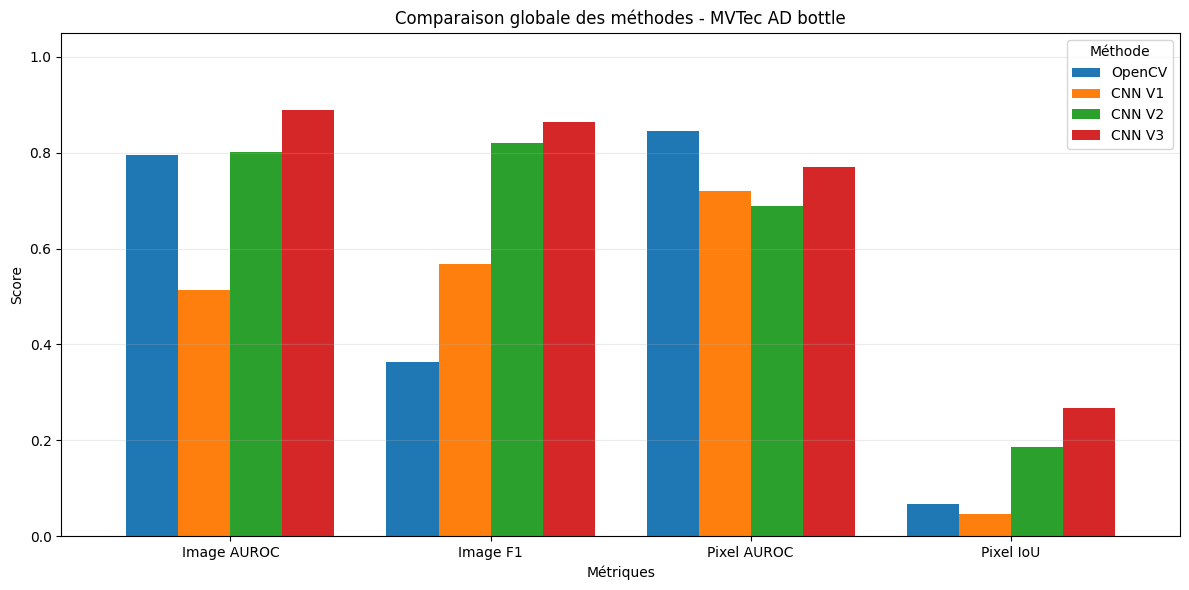

Figure globale sauvegardée : /content/drive/MyDrive/industrial-anomaly-detection/outputs/figures/comparison_all_methods.png


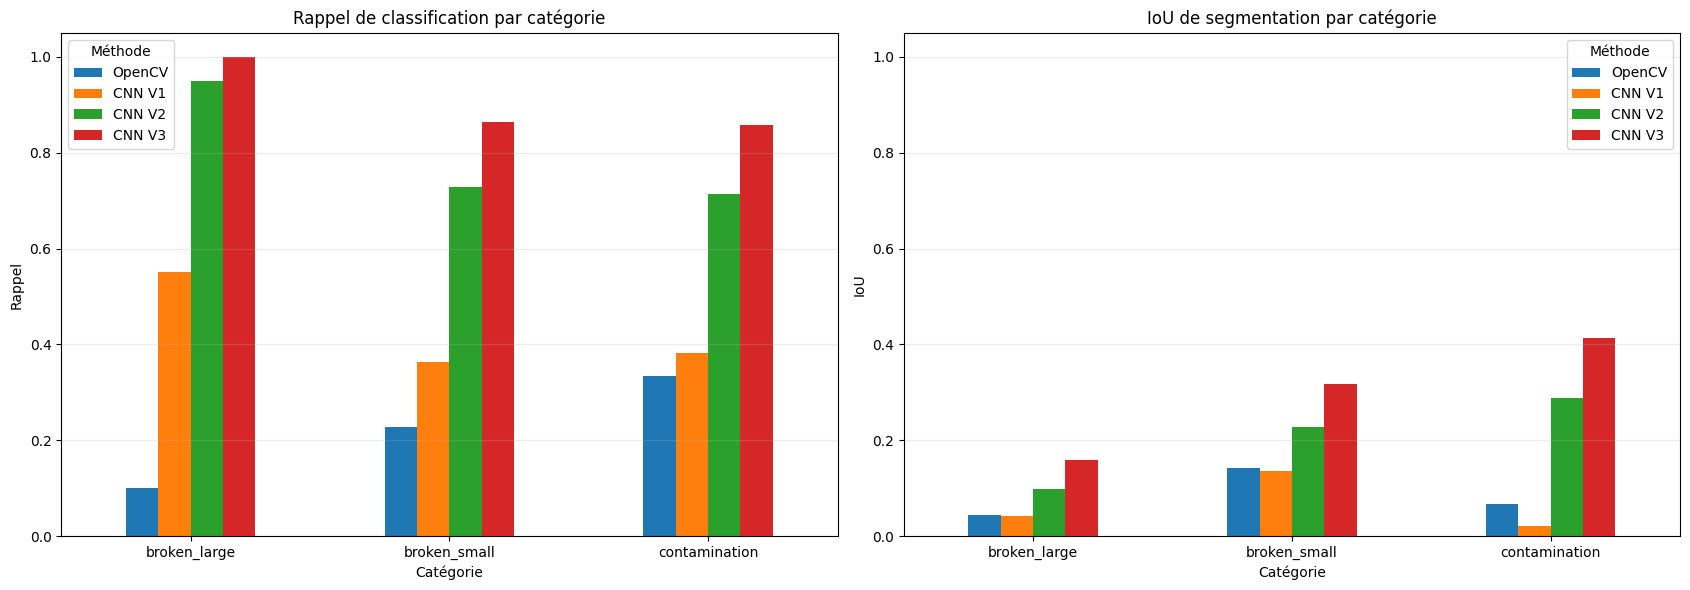

Figure par catégorie sauvegardée : /content/drive/MyDrive/industrial-anomaly-detection/outputs/figures/comparison_by_category.png

=== FAUSSES ALERTES SUR LES IMAGES NORMALES ===
Méthode  Alertes  Images  Taux d'alerte
 OpenCV        0      20           0.00
 CNN V1        5      20           0.25
 CNN V2        9      20           0.45
 CNN V3       12      20           0.60

Visualisations terminées.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

assert MODE == "experimentation", "Sélectionner le mode expérimentation"
assert "comparison_all_df" in globals()
assert "comparison_by_category_df" in globals()

# 1. Répertoire de sauvegarde des figures
figure_dir = DRIVE_PROJECT / "outputs" / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

methods = ["OpenCV", "CNN V1", "CNN V2", "CNN V3"]

# ==================================================
# FIGURE 1 - COMPARAISON GLOBALE
# ==================================================

global_metrics = ["Image AUROC", "Image F1", "Pixel AUROC", "Pixel IoU"]

global_plot_df = comparison_all_df.set_index("Méthode").loc[methods, global_metrics]

ax = global_plot_df.T.plot(kind="bar", figsize=(12, 6), rot=0, width=0.8)

ax.set_title("Comparaison globale des méthodes - MVTec AD bottle")
ax.set_xlabel("Métriques")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)

ax.legend(title="Méthode", loc="upper right")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

global_figure_path = figure_dir / "comparison_all_methods.png"

plt.savefig(global_figure_path, dpi=200, bbox_inches="tight")
plt.show()

print("Figure globale sauvegardée :", global_figure_path)

# ===================================================
# FIGURE 2 - COMPARAISON PAR CATEGORIE
# ===================================================

defect_categories = ["broken_large", "broken_small", "contamination"]
category_data = comparison_by_category_df[comparison_by_category_df["Catégorie"].isin(defect_categories)].copy()

# Taux de détection des images
recall_df = category_data.pivot(index="Catégorie", columns="Méthode", values="Taux d'alerte").loc[defect_categories, methods]

# IoU de segmentation
iou_df = category_data.pivot(index="Catégorie", columns="Méthode", values="Pixel IoU").loc[defect_categories, methods]

fig, axes = plt.subplots(1, 2, figsize=(17, 6))

# Graphique de classification
recall_df.plot(kind="bar", ax=axes[0], rot=0)

axes[0].set_title("Rappel de classification par catégorie")
axes[0].set_xlabel("Catégorie")
axes[0].set_ylabel("Rappel")
axes[0].set_ylim(0, 1.05)
axes[0].legend(title="Méthode")
axes[0].grid(axis="y", alpha=0.25)

# Graphique de segmentation
iou_df.plot(kind="bar", ax=axes[1], rot=0)

axes[1].set_title("IoU de segmentation par catégorie")
axes[1].set_xlabel("Catégorie")
axes[1].set_ylabel("IoU")
axes[1].set_ylim(0, 1.05)
axes[1].legend(title="Méthode")
axes[1].grid(axis="y", alpha=0.25)

plt.tight_layout()

category_figure_path = figure_dir / "comparison_by_category.png"
plt.savefig(category_figure_path, dpi=200, bbox_inches="tight")

plt.show()

print("Figure par catégorie sauvegardée :", category_figure_path)


# =========================================================
# RAPPEL : FAUSSES ALERTES SUR LES IMAGES NORMALES
# =========================================================

normal_results = comparison_by_category_df[comparison_by_category_df["Catégorie"] == "good"][["Méthode", "Alertes", "Images", "Taux d'alerte"]]

print("\n=== FAUSSES ALERTES SUR LES IMAGES NORMALES ===")
print(normal_results.to_string(index=False))

print("\nVisualisations terminées.")

***5.5 — Bilan expérimental***

Cette section compare quatre approches de détection d'anomalies sur la catégorie `bottle` du dataset MVTec AD :

- **OpenCV** : différence avec une image moyenne de référence.
- **CNN V1** : erreur de reconstruction d'un autoencodeur convolutif.
- **CNN V2** : normalisation spatiale des erreurs de reconstruction.
- **CNN V3** : lissage gaussien des cartes normalisées.

### Résultats principaux

- **OpenCV** constitue une baseline simple, rapide et interprétable.
- **CNN V1** améliore la détection d'image, mais reste faible en segmentation.
- **CNN V2** apporte une amélioration importante grâce à la normalisation spatiale.
- **CNN V3** obtient les meilleures performances globales en classification et en IoU de segmentation.

### Conclusion expérimentale

La méthode **CNN V3** est la meilleure variante testée dans ce projet :

- meilleur **Image AUROC** ;
- meilleur **Image F1-score** ;
- meilleure **IoU de segmentation**.

Cependant, cette amélioration s'accompagne d'une hausse des **fausses alertes sur les images normales**, ce qui montre que la sensibilité du modèle reste encore trop élevée.

### Limites

- Les résultats restent **exploratoires**, car les images de test ont été utilisées plusieurs fois pendant le développement.
- La segmentation des défauts reste partielle, en particulier pour les régions étendues.
- Les masques produits ne couvrent pas encore totalement les zones anormales.

### Perspectives

Pour améliorer la qualité des masques, plusieurs pistes restent possibles :

- augmentation de la résolution d'entrée ;
- amélioration de l'architecture CNN ;
- meilleure fonction de perte ;
- post-traitement plus avancé ;
- méthodes plus modernes comme **PatchCore**.

Dans l'état actuel, le projet constitue un **prototype fonctionnel et cohérent** de détection et localisation d'anomalies sur images industrielles.

# ***6. Résultats et visualisations finales***

Cette section présente les résultats visuels et les conclusions de notre projet de détection et localisation d'anomalies industrielles.

Les quatre méthodes étudiées sont comparées sur des exemples issus de MVTec AD `bottle`.

**Objectifs :**
- Comparer les masques prédits aux annotations de vérité terrain.
- Visualiser les défauts correctement localisés et les erreurs de segmentation.
- Synthétiser les performances des méthodes.
- Présenter les limites et les perspectives d'amélioration.

Les visualisations sont sauvegardées sur Google Drive pour la documentation du projet.

**Remarque :** les résultats sont exploratoires, le jeu de test ayant déjà été utilisé pendant le développement.

***6.1 — Comparaison visuelle des segmentations***

**Mode expérimentation — Visualisation finale**

Comparaison des masques prédits par OpenCV, CNN V1, CNN V2 et CNN V3 avec les annotations de vérité terrain.

Une visualisation des erreurs de la V3 permet d'identifier :

- Les pixels défectueux correctement détectés (vert).
- Les pixels normaux détectés à tort (rouge).
- Les pixels défectueux non détectés (bleu).

Un exemple est sélectionné de manière déterministe pour chaque catégorie.

La figure est sauvegardée sur Google Drive.

good : 000.png | TP=0, FP=518, FN=0
broken_large : 000.png | TP=1622, FP=336, FN=5508
broken_small : 000.png | TP=199, FP=222, FN=383
contamination : 000.png | TP=1186, FP=297, FN=3568


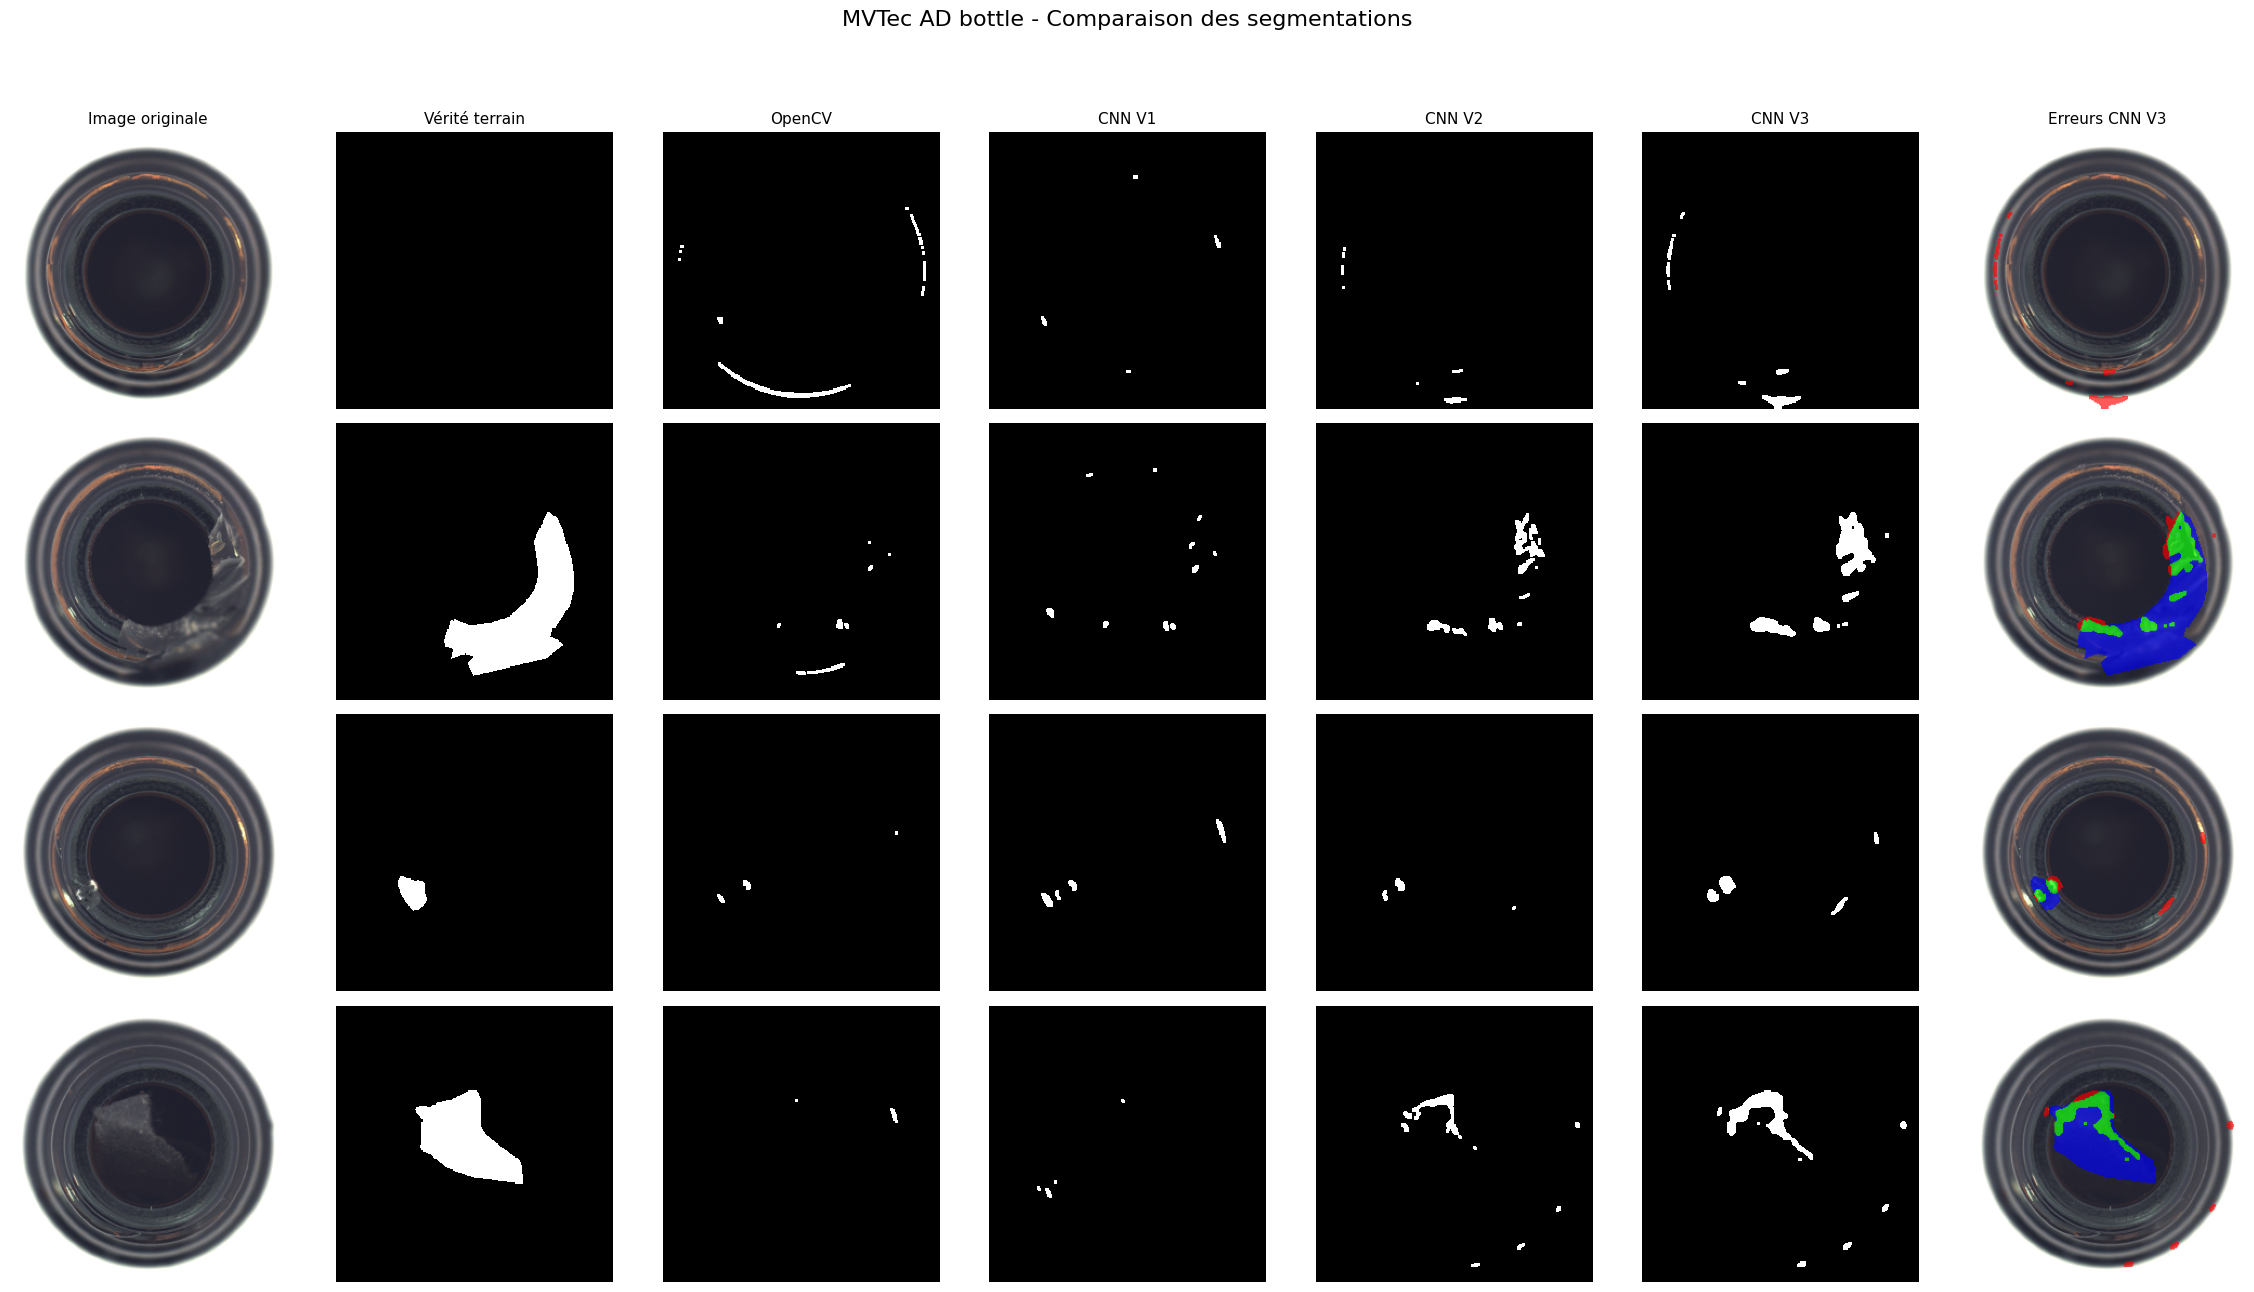


Figure sauvegardée : /content/drive/MyDrive/industrial-anomaly-detection/outputs/figures/segmentation_all_methods_final.png


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

assert MODE == "experimentation", "Sélectionner le mode expérimentation"

categories = ["good", "broken_large", "broken_small", "contamination"]
titles = ["Image originale", "Vérité terrain", "OpenCV", "CNN V1", "CNN V2", "CNN V3", "Erreurs CNN V3"]

kernel = np.ones((3, 3), dtype=np.uint8)

fig, axes = plt.subplots(4, 7, figsize=(23, 13))

for row, category in enumerate(categories):

    # 1. Sélection reproductible d'une image
    image_paths = sorted((BOTTLE_DIR / "test" / category).glob("*png"))
    assert image_paths, f"Aucune image trouvée pour la catégorie {category}"

    image_path = image_paths[0]
    image = load_image(image_path)

    # 2. Vérité terrain
    if category == "good":
        gt_mask = np.zeros((256, 256), dtype=np.uint8)
    else:
        mask_path = BOTTLE_DIR / "ground_truth" / category / f"{image_path.stem}_mask.png"
        gt_mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
        assert gt_mask is not None, f"Masque introuvable : {mask_path}"
        gt_mask = cv2.resize(gt_mask, (256, 256), interpolation=cv2.INTER_NEAREST)
        gt_mask = (gt_mask > 0).astype(np.uint8)

    # 3. Segmentation OpenCV
    opencv_map = cv2.GaussianBlur(
        np.mean(cv2.absdiff(image, reference_image), axis=2),
        (5, 5), 0
    )

    opencv_mask = (opencv_map > pixel_threshold).astype(np.uint8)
    opencv_mask = cv2.morphologyEx(opencv_mask, cv2.MORPH_OPEN, kernel)

    # 4. Segmentation CNN V1 / V2 / V3
    cnn_maps = generate_cnn_maps(image)
    cnn_masks = generate_cnn_masks(cnn_maps)

    # 5. Diagnostic des erreurs de segmentation V3
    v3_mask = cnn_masks["V3"]

    tp = (v3_mask == 1) & (gt_mask == 1)
    fp = (v3_mask == 1) & (gt_mask == 0)
    fn = (v3_mask == 0) & (gt_mask == 1)

    # Superposition des erreurs sur l'image originale
    overlay = image.copy()
    alpha = 0.65

    for region, color in [
        (tp, (0, 1, 0)),      # Vert
        (fp, (1, 0, 0)),      # Rouge
        (fn, (0, 0, 1))       # Bleu
    ]:
        color = np.asarray(color, dtype=np.float32)
        overlay[region] = (1 - alpha) * image[region] + alpha * color

    # 6. Affichage des sept colonnes
    panels = [
        image, gt_mask, opencv_mask, cnn_masks["V1"], cnn_masks["V2"], cnn_masks["V3"] , overlay
    ]

    for col, panel in enumerate(panels):
        ax = axes[row, col]
        if col in (0, 6):
            ax.imshow(panel)
        else:
            ax.imshow(panel, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
        ax.axis("off")

    axes[row, 0].set_ylabel(category, fontsize=11)

    print(
        f"{category} : {image_path.name} | "
        f"TP={int(tp.sum())}, "
        f"FP={int(fp.sum())}, "
        f"FN={int(fn.sum())}"
    )

# 7. Titres des colonnes
for col, title in enumerate(titles):
    axes[0, col].set_title(title, fontsize=11)

fig.suptitle("MVTec AD bottle - Comparaison des segmentations", fontsize=16, y=0.99)
plt.tight_layout(rect=[0, 0, 1, 0.95])

# 8. Sauvegarde permanente
figure_dir = DRIVE_PROJECT / "outputs" / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

figure_path = figure_dir / "segmentation_all_methods_final.png"
plt.savefig(figure_path, dpi=200, bbox_inches="tight")

plt.show()

print("\nFigure sauvegardée :", figure_path)

***6.2 — Synthèse des résultats expérimentaux***

### Performances globales

Les quatre méthodes ont été évaluées sur les 83 images de test de la catégorie `bottle` du dataset MVTec AD.

| Méthode | Image AUROC | Image F1 | Pixel AUROC | Pixel IoU |
|---|---:|---:|---:|---:|
| OpenCV | 0.7952 | 0.3636 | **0.8455** | 0.0667 |
| CNN V1 | 0.5135 | 0.5684 | 0.7199 | 0.0472 |
| CNN V2 | 0.8016 | 0.8197 | 0.6892 | 0.1857 |
| CNN V3 | **0.8881** | **0.8636** | 0.7693 | **0.2682** |

### Résultats de classification

La méthode CNN V3 obtient les meilleures performances de classification :

- Image AUROC : **88,81 %**.
- F1-score : **86,36 %**.
- Détection de 57 images défectueuses sur 63.
- Identification correcte de 8 images normales sur 20.

Cependant, 12 images normales sur 20 déclenchent une fausse alerte, soit un taux de 60 %.

La V3 présente donc une forte sensibilité aux anomalies, mais une spécificité insuffisante.

### Résultats de segmentation

La normalisation spatiale des erreurs CNN V2 améliore fortement l'IoU par rapport à l'erreur de reconstruction brute V1.

Le lissage gaussien introduit dans la V3 améliore encore la couverture des régions défectueuses :

- IoU CNN V1 : **4,72 %**.
- IoU CNN V2 : **18,57 %**.
- IoU CNN V3 : **26,82 %**.

Néanmoins, la V3 conserve un rappel pixel relativement faible, de **31,07 %**.

L'analyse visuelle montre que les cartes d'anomalies réagissent principalement aux contours et aux variations locales de texture, sans couvrir systématiquement l'intégralité des régions défectueuses.

### Conclusion de la comparaison

La CNN V3 constitue la meilleure variante expérimentale du projet pour la classification et l'IoU de segmentation.

Cependant, OpenCV conserve le meilleur Pixel AUROC, ce qui montre qu'aucune méthode ne domine tous les critères.

Les résultats restent exploratoires, le jeu de test ayant également servi aux diagnostics pendant le développement.

***6.3 — Limites et perspectives d'amélioration***

### 6.3.1 — Limites de la détection

Bien que la méthode CNN V3 obtienne les meilleures performances de classification du projet, plusieurs limitations subsistent.

**1. Taux de fausses alertes élevé**

La CNN V3 détecte 57 des 63 images défectueuses, mais classe également 12 des 20 images normales comme anormales.

Son rappel de classification atteint **90,48 %**, tandis que son taux de fausses alertes atteint **60 %**.

Cette sensibilité élevée pourrait être problématique dans un contexte industriel, où des alertes injustifiées peuvent entraîner des inspections supplémentaires ou des interruptions inutiles.

**2. Difficulté à distinguer certaines variations normales**

Les cartes d'anomalies présentent des activations sur les contours circulaires et les textures normales des bouteilles.

Ces variations peuvent provenir de différences d'alignement, d'éclairage ou de reconstruction.

La normalisation spatiale et le lissage améliorent certaines détections, mais n'éliminent pas complètement ces erreurs.

### 6.3.2 — Limites de la segmentation

**1. Couverture incomplète des régions défectueuses**

Malgré une amélioration de l'IoU globale de **4,72 % (CNN V1)** à **26,82 % (CNN V3)**, les masques prédits restent partiels.

Le rappel pixel de la V3 atteint seulement **31,07 %**, ce qui signifie qu'environ 69 % des pixels réellement défectueux ne sont pas détectés.

Les figures montrent notamment que les activations se concentrent sur les contours et les régions présentant de fortes différences visuelles.

**2. Perte de détails lors du redimensionnement**

Les images originales de la catégorie `bottle` mesurent 900 × 900 pixels, mais sont redimensionnées à 256 × 256 pixels.

Cette réduction peut atténuer les petits défauts, supprimer certains détails et rendre leurs frontières moins précises.

**3. Limites de l'erreur de reconstruction**

L'autoencodeur est entraîné avec une fonction de perte MSE sur des images normales.

Cependant, une erreur de reconstruction élevée ne correspond pas nécessairement à une anomalie. Inversement, certaines régions défectueuses peuvent être partiellement reconstruites.

Le seuillage de ces erreurs ne garantit donc pas la récupération de l'intégralité des régions défectueuses.

### 6.3.3 — Limites expérimentales

Le projet a été développé et évalué uniquement sur la catégorie `bottle` de MVTec AD.

L'ensemble d'entraînement contient 209 images normales, réparties en 167 images d'entraînement et 42 images de validation.

Les statistiques spatiales de la V2 reposent sur seulement 21 images normales, les 21 autres servant à la calibration.

Cette taille limitée peut affecter la robustesse des statistiques et des seuils estimés.

De plus, les 83 images de test ont été consultées à plusieurs reprises pendant le développement. Les performances présentées doivent donc être considérées comme **exploratoires**, et non comme une évaluation indépendante définitive.

### 6.3.4 — Perspectives d'amélioration

**A. Amélioration de la résolution et du prétraitement**

- Tester des résolutions de 384 × 384 et 512 × 512 pixels.
- Étudier l'alignement des bouteilles avant la comparaison.
- Évaluer l'influence des variations d'éclairage.
- Recalibrer les seuils pour chaque nouvelle configuration.

**B. Amélioration de l'autoencodeur**

- Expérimenter différentes capacités de compression.
- Comparer la perte MSE à une combinaison de L1 et de SSIM.
- Tester un autoencodeur débruiteur.
- Étudier une augmentation réaliste des données normales.

**C. Utilisation de caractéristiques visuelles préentraînées**

Tester une méthode telle que **PatchCore**, fondée sur la comparaison de caractéristiques locales extraites par un réseau préentraîné avec celles d'images normales.

Cette approche pourrait mieux représenter certaines variations de texture et de structure que les seules différences RGB.

**D. Amélioration de la segmentation**

- Étudier des traitements morphologiques adaptés aux défauts.
- Comparer plusieurs stratégies de génération des cartes d'anomalies.
- Analyser les compromis entre précision et rappel.
- Étudier la calibration des seuils avec davantage d'images normales.

**E. Évaluation et généralisation**

- Tester d'autres catégories de MVTec AD.
- Utiliser un jeu d'évaluation indépendant pour les futures versions.
- Mesurer la stabilité des résultats sur plusieurs répartitions de validation.
- Évaluer les coûts de calcul et la latence d'inférence.

### 6.3.5 — Synthèse

Les expérimentations démontrent que la normalisation spatiale et le lissage des erreurs de reconstruction permettent d'améliorer les performances de l'autoencodeur initial, sans modifier ses poids.

Toutefois, la qualité des masques et le taux de fausses alertes montrent que le système reste un prototype expérimental.

Les améliorations futures devront chercher un meilleur équilibre entre **détection fiable, localisation précise et limitation des fausses alertes**.


***6.4 — Conclusion générale du projet***

### Objectif et réalisations

Ce projet avait pour objectif de développer un pipeline de **détection et de localisation d'anomalies visuelles sur des images industrielles**, en combinant des techniques classiques de traitement d'images et une approche d'apprentissage profond.

Les expérimentations ont été réalisées sur la catégorie `bottle` du dataset **MVTec AD**, à l'aide de Python, OpenCV, PyTorch et scikit-learn.

Quatre méthodes ont été développées et comparées :

1. **OpenCV** — Détection par comparaison avec une image moyenne de référence.
2. **CNN V1** — Détection à partir des erreurs de reconstruction d'un autoencodeur convolutif.
3. **CNN V2** — Normalisation spatiale des erreurs de reconstruction.
4. **CNN V3** — Normalisation spatiale suivie d'un lissage gaussien.

Les trois variantes CNN utilisent le même autoencodeur, entraîné uniquement sur des images normales.

### Principaux résultats

L'évaluation exploratoire sur 83 images de test montre une amélioration progressive des performances de l'autoencodeur grâce aux traitements appliqués aux cartes d'anomalies.

| Méthode | Image AUROC | Image F1 | Pixel IoU |
|---|---:|---:|---:|
| OpenCV | 0.7952 | 0.3636 | 0.0667 |
| CNN V1 | 0.5135 | 0.5684 | 0.0472 |
| CNN V2 | 0.8016 | 0.8197 | 0.1857 |
| CNN V3 | **0.8881** | **0.8636** | **0.2682** |

La méthode **CNN V3** obtient les meilleures performances de classification, mesurées par l'AUROC et le F1-score, ainsi que la meilleure IoU de segmentation parmi les approches testées.

Elle détecte **57 des 63 images défectueuses**, soit un rappel de classification de **90,48 %**.

Cependant, elle génère également **12 fausses alertes sur 20 images normales**, et son rappel pixel reste limité à **31,07 %**.

La méthode OpenCV conserve par ailleurs le meilleur Pixel AUROC, avec **0,8455**.

### Apports techniques

Ce projet a permis de mettre en œuvre un pipeline complet comprenant :

- L'exploration et le prétraitement d'images industrielles.
- La construction d'une méthode de référence avec OpenCV.
- La conception et l'entraînement d'un autoencodeur convolutif avec PyTorch.
- La génération de cartes d'anomalies et de masques de segmentation.
- La calibration de seuils sur des images normales.
- La comparaison quantitative des approches par des métriques de classification et de segmentation.
- L'analyse des faux positifs, des faux négatifs et des erreurs de localisation.
- La sauvegarde et la restauration des modèles, des paramètres et des résultats expérimentaux.

### Conclusion

Les expérimentations montrent que **les erreurs de reconstruction d'un autoencodeur peuvent être exploitées pour détecter des anomalies industrielles**, mais que leur seuillage direct présente des limites importantes pour la segmentation.

La normalisation spatiale et le lissage gaussien améliorent le recouvrement des régions défectueuses sans nécessiter de réentraîner le réseau.

Néanmoins, la qualité des masques demeure insuffisante pour envisager une utilisation industrielle fiable sans améliorations supplémentaires.

Les résultats présentés restent exploratoires, car le jeu de test a également été utilisé lors des diagnostics et de l'élaboration des variantes.

Ce projet constitue ainsi un **prototype fonctionnel de détection et de localisation d'anomalies**, ainsi qu'une base pour de futures expérimentations sur la résolution des images, les architectures neuronales et les méthodes fondées sur des caractéristiques préentraînées, notamment PatchCore.
